In [1]:
import os
import pandas as pd
import re
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import skew

**Loading Dataset**

In [2]:
from google.colab import drive

drive.mount('/content/drive')
FOLDER_PATH = '/content/drive/MyDrive/DS_project'

ID_COLUMNS = ["hhcode", "idc"]   # pure identifiers, no labels

def read_stata_labeled(path):
    """Load a .dta with text labels. If duplicate label text breaks pandas,
    apply the labels manually and make duplicates unique, e.g. 'hand pump (2)'."""
    try:
        df = pd.read_stata(path, convert_categoricals=True)
    except ValueError as e:
        if "not unique" not in str(e):
            raise
        print(f"  [!] {os.path.basename(path)}: duplicate labels -> de-duplicating")
        with pd.io.stata.StataReader(path) as sr:
            df = sr.read(convert_categoricals=False)
            varlist, lbllist, value_labels = sr._varlist, sr._lbllist, sr.value_labels()
        for col, lblname in zip(varlist, lbllist):
            if lblname and lblname in value_labels and col in df.columns:
                seen, mapping = {}, {}
                for code, text in value_labels[lblname].items():
                    seen[text] = seen.get(text, 0) + 1
                    mapping[code] = text if seen[text] == 1 else f"{text} ({seen[text]})"
                df[col] = df[col].map(mapping).fillna(df[col])
    # make ID columns the same type in every file (values unchanged)
    for col in ID_COLUMNS:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")
    return df

datasets = {
    "education": "sec_2ab_education.dta", "consum_exp": "sec_6a_consum_exp.dta",
    "sec_7": "sec_7.dta", "sec_8a": "sec_8a.dta", "sec_9a": "sec_9a.dta", "sec_9b": "sec_9b.dta",
    "weight": "weight.dta", "plist_roster": "plist_roster.dta", "emp_income": "sec_1b_emp_income.dta",
    "ict": "sec_02c_ict.dta", "diarrhoea": "Sec_03a_diarrhoea.dta", "immunisation": "Sec_03b_immunisation.dta",
    "malaria": "sec_03c_malaria.dta", "pregnancyhistory": "Sec_04a_pregnancyhistory.dta",
    "maternityhistory": "sec_04b_maternityhistory.dta", "familyplanning": "sec_04c_familyplanning.dta",
    "pre_post_natal": "Sec_04d_pre_post_natal.dta", "decisionmaking": "Sec_04e_decisionmaking.dta",
    "housingchar": "sec_05m1_housingchar.dta", "watersanitation": "sec_05m2_watersanitation.dta",
    "wastemanagment": "sec_05m3_wastemanagment.dta", "fies": "sec_05m4_fies.dta",
    "agrisheet": "sec_10a_agrisheet.dta", "livestock": "sec_10b_livestock.dta",
    "nonagri": "sec_11ab_nonagri.dta", "section_info": "section_info.dta",
}

dataframes = {}
for name, filename in datasets.items():
    dataframes[name] = read_stata_labeled(os.path.join(FOLDER_PATH, filename))
    print(f"Loaded: {name} {dataframes[name].shape}")

# Assign to the variable names used in the merge cell
globals().update({f"{k}_df": v for k, v in dataframes.items()})

Mounted at /content/drive
Loaded: education (170901, 20)
  [!] sec_6a_consum_exp.dta: duplicate labels -> de-duplicating
Loaded: consum_exp (2396159, 17)
Loaded: sec_7 (275914, 10)
Loaded: sec_8a (1204354, 8)
Loaded: sec_9a (149868, 36)
Loaded: sec_9b (632119, 8)
Loaded: weight (2153, 2)
Loaded: plist_roster (184564, 20)
Loaded: emp_income (134468, 35)
Loaded: ict (161203, 110)
Loaded: diarrhoea (22934, 31)
Loaded: immunisation (22934, 49)
Loaded: malaria (183967, 48)
Loaded: pregnancyhistory (44103, 25)
Loaded: maternityhistory (80978, 18)
Loaded: familyplanning (28567, 50)
Loaded: pre_post_natal (29601, 28)
Loaded: decisionmaking (44155, 19)
Loaded: housingchar (30123, 74)
  [!] sec_05m2_watersanitation.dta: duplicate labels -> de-duplicating
Loaded: watersanitation (30123, 30)
Loaded: wastemanagment (30123, 11)
Loaded: fies (30123, 14)
  [!] sec_10a_agrisheet.dta: duplicate labels -> de-duplicating
Loaded: agrisheet (150530, 14)
  [!] sec_10b_livestock.dta: duplicate labels -> de-du

/tmp/ipykernel_1411/496285241.py:26: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[col] = df[col].map(mapping).fillna(df[col])


  [!] sec_11ab_nonagri.dta: duplicate labels -> de-duplicating
Loaded: nonagri (128699, 14)
Loaded: section_info (30123, 9)


***Section 1***

**Merging Data**

In [3]:
# ============================================================
# MEGA MERGE: all files onto the roster
# Individual-level keys: prcode + hhno + idc
# Household-level keys : prcode + hhno
# (falls back to hhcode if a file has no prcode/hhno)
# ============================================================
IND_KEYS = ["prcode", "hhno", "idc"]
HH_KEYS  = ["prcode", "hhno"]
ALL_ID_COLS = ["hhcode", "prcode", "hhno", "idc", "province", "region", "quater"]

def norm_keys(df):
    """Copy with key columns in one common type (numeric if it converts cleanly, else stripped text)."""
    df = df.copy()
    for k in ["hhcode", "prcode", "hhno", "idc"]:
        if k in df.columns:
            num = pd.to_numeric(df[k], errors="coerce")
            if num.isna().sum() == df[k].isna().sum():
                df[k] = num.astype("Int64")
            else:
                df[k] = df[k].astype("string").str.strip()
    return df

def pick_keys(df):
    """Decide the merge level of a file. Returns (level, keys) or (None, reason)."""
    has = lambda cols: all(c in df.columns for c in cols)
    for level, cands in [("individual", [IND_KEYS, ["hhcode", "idc"]]),
                         ("household",  [HH_KEYS,  ["hhcode"]])]:
        for keys in cands:
            if has(keys) and not df.duplicated(subset=keys).any():
                return level, keys
    return None, "no unique key (multiple rows per household/person)"

roster_n = norm_keys(plist_roster_df)
assert not roster_n.duplicated(subset=IND_KEYS).any(), "Roster is not unique on prcode+hhno+idc!"

# Every file except the roster, in the merge order
merge_order = [n for n in datasets if n != "plist_roster"]

merged = roster_n
report, skipped = [], []

for name in merge_order:
    df = norm_keys(dataframes[name])
    level, keys = pick_keys(df)

    if level is None:
        skipped.append(name)
        report.append((name, "SKIPPED", keys, len(df), None))
        continue

    # drop repeated ID/geo columns that are not the merge key (roster keeps them)
    right = df.drop(columns=[c for c in ALL_ID_COLS if c in df.columns and c not in keys])
    before_cols = merged.shape[1]
    merged = pd.merge(merged, right, on=keys, how="left",
                      suffixes=("", f"_{name}"),
                      validate="m:1" if level == "household" else "1:1")
    report.append((name, level, "+".join(keys), len(df), merged.shape[1] - before_cols))

final_df = merged

# ---------------- Reports ----------------
print(f"Roster rows: {len(roster_n)} | Final rows: {len(final_df)} | Final shape: {final_df.shape}\n")
summary = pd.DataFrame(report, columns=["file", "level", "keys", "file_rows", "cols_added"])
print(summary.to_string(index=False))

if len(final_df) != len(roster_n):
    print("\n Row count changed — check the file merged last.")
if skipped:
    print("\nNot merged (multiple rows per household/person, would multiply rows):", skipped)

final_df

Roster rows: 184564 | Final rows: 184564 | Final shape: (184564, 479)

            file      level                                               keys  file_rows  cols_added
       education individual                                    prcode+hhno+idc     170901        14.0
      consum_exp    SKIPPED no unique key (multiple rows per household/person)    2396159         NaN
           sec_7    SKIPPED no unique key (multiple rows per household/person)     275914         NaN
          sec_8a    SKIPPED no unique key (multiple rows per household/person)    1204354         NaN
          sec_9a    SKIPPED no unique key (multiple rows per household/person)     149868         NaN
          sec_9b    SKIPPED no unique key (multiple rows per household/person)     632119         NaN
          weight    SKIPPED no unique key (multiple rows per household/person)       2153         NaN
      emp_income individual                                    prcode+hhno+idc     134468        28.0
           

,prcode,hhno,idc,province,region,quater,s1aq02,s1aq03,s1aq04,s1aq51,...,q3,q4,q5,q6,q7,q8,fstatus,enum_month,enum_day,enum_year
0,11021001,1,1,kp,urban,1,head,male,present,52,...,yes,yes,refused,98,refused,refused,completed,10,19,2024
1,11021001,1,2,kp,urban,1,son/daughter,male,present,13,...,yes,yes,refused,98,refused,refused,completed,10,19,2024
2,11021001,1,3,kp,urban,1,son/daughter,male,present,12,...,yes,yes,refused,98,refused,refused,completed,10,19,2024
3,11021001,1,51,kp,urban,1,spous,female,present,36,...,yes,yes,refused,98,refused,refused,completed,10,19,2024
4,11021001,1,52,kp,urban,1,son/daughter,female,present,15,...,yes,yes,refused,98,refused,refused,completed,10,19,2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
184559,61114008,119,1,punjab,rural,4,head,male,present,47,...,yes,yes,yes,yes,dont know,refused,completed,5,22,2025
184560,61114008,119,2,punjab,rural,4,son/daughter,male,present,12,...,yes,yes,yes,yes,dont know,refused,completed,5,22,2025
184561,61114008,119,51,punjab,rural,4,spous,female,present,39,...,yes,yes,yes,yes,dont know,refused,completed,5,22,2025
184562,61114008,119,52,punjab,rural,4,son/daughter,female,present,18,...,yes,yes,yes,yes,dont know,refused,completed,5,22,2025


In [4]:
# Master Dataset Overview:
# 1. Check total rows vs unique individuals
total_rows = len(final_df)
unique_individuals = final_df[["prcode", "hhno", "idc"]].drop_duplicates().shape[0]

print(f"Total rows in final_df: {total_rows:,}")
print(f"Unique individuals (prcode + hhno + idc): {unique_individuals:,}")

# 2. Assert uniqueness (stops execution if duplicates are found)
assert (
    total_rows == unique_individuals
), f"Mismatch! Found {total_rows - unique_individuals} duplicate individual entries."
print("Success: Every individual entry in final_df is 100% unique!")


Total rows in final_df: 184,564
Unique individuals (prcode + hhno + idc): 184,564
Success: Every individual entry in final_df is 100% unique!


**Summary of Merged Data**

In [5]:
import os
import pandas as pd

# 1. Collect variable labels (descriptions) from ALL source .dta files
var_labels = {}
for name, filename in datasets.items():
    path = os.path.join(FOLDER_PATH, filename)
    try:
        with pd.read_stata(path, iterator=True) as reader:
            var_labels.update(reader.variable_labels())
    except Exception as e:
        print(f"Could not read labels for {filename}: {e}")

# 2. Helper to strip merge suffixes dynamically
suffixes_to_strip = [
    f"_{name}" for name in datasets.keys() if name != "plist_roster"
]


def base_column_name(col):
    # Remove feature-engineered suffix '_missing' if present to capture base Stata label
    if col.endswith("_missing"):
        col = col[:-8]
    for suf in sorted(suffixes_to_strip, key=len, reverse=True):
        if col.endswith(suf):
            return col[:-len(suf)]
    return col


# 3. Build summary table for df_modeling
column_summary = pd.DataFrame(
    {
        "Variable Name": final_df.columns,
        "Variable Description": [
            var_labels.get(base_column_name(col), "—") for col in final_df.columns
        ],
        "Valid Count": final_df.notna().sum().values,
        "Missing Count": final_df.isna().sum().values,
        "Valid (%)": (final_df.notna().mean() * 100).round(2).values,
        # Lists unique values for each variable (capped at first 10 for readability)
        "Unique Values": [
            final_df[col].dropna().unique()[:10].tolist()
            for col in final_df.columns
        ],
    }
)

# 4. Display sorted from highest valid count to lowest
column_summary_sorted = column_summary.sort_values(
    by="Valid Count", ascending=False
).reset_index(drop=True)

# Print the column summary table
print(column_summary_sorted.to_string())

# ============================================================
# 5. Save the summary table to CSV (df_modeling summary)
# ============================================================
csv_path = os.path.join(FOLDER_PATH, "df_modeling_summary.csv")
column_summary_sorted.to_csv(csv_path, index=False)
print(f"Summary table successfully saved to: {csv_path}")

# ============================================================
# 6. Total Dataset Valid Percentage Summary for df_modeling
# ============================================================
total_rows = len(final_df)
total_cols = len(final_df.columns)
total_cells = final_df.size
total_valid_cells = final_df.notna().sum().sum()
overall_valid_pct = (total_valid_cells / total_cells) * 100

print("\n" + "=" * 60)
print("DF_MODELING DATASET COMPLETENESS SUMMARY")
print("=" * 60)
print(f"Total Rows: {total_rows:,}")
print(f"Total Columns: {total_cols:,}")
print(f"Total Cells (Size): {total_cells:,}")
print(f"Total Valid (Non-Missing) Cells: {total_valid_cells:,}")
print(f"Overall Dataset Valid Percentage: {overall_valid_pct:.2f}%")
print("=" * 60)

              Variable Name                                                              Variable Description  Valid Count  Missing Count  Valid (%)                                                                                                                                                                                                                                                                                                                                                                         Unique Values
0                 enum_year                                                                                         184564              0     100.00                                                                                                                                                                                                                                                                                                                                         

**Cleaning Data (Dropping)**

### Part 1: Initial Column Dropping (Data Minimization & Quality Screening)

In this first step of data cleaning, we drop **49 unusable columns** from the merged HIES dataset based on three explicit quality criteria:

1. **Zero Variance / Constant Administrative Flags (1 Column):**
   - **`fstatus`**: Contains the identical string value (`"completed"`) across all observations. Because it offers zero statistical variance, it provides no analytical utility.

2. **Extreme Sparsity / Missingness (15 Columns):**
   - Columns containing **\(\le 25\) valid observations** out of $184,564$ total rows (\(>99.99\%\) missingness).
   - These columns (e.g., zero-entry indicators or single-digit response flags) cannot support statistical modeling, subgroup comparisons, or reliable imputation.

3. **Unanalysable Free-Text / Numeric "Other (Specify)" Fields (33 Columns):**
   - Fields ending in `ot`, `oth`, or `10t` that capture open-ended responses when respondents chose "other".
   - These contain unlabelled numeric codes, unstandardized text, or blank strings that artificially distort missingness metrics without providing structured data.

*Note: Demographically restricted modules (e.g., child health or contraception) are kept in the archive dataset rather than dropped, preserving all secondary information.*

In [6]:
# =============================================================================
# PART 1: DROP UNNECESSARY & UNANALYSABLE COLUMNS
# =============================================================================

# 1. Zero Variance / Constant Administrative Flags
single_value_cols = [
    'fstatus'  # Single value ('completed') for every row; provides zero statistical variance
]

# 2. Extreme Sparsity / Missingness (<= 25 valid entries out of 184,564 rows)
sparse_cols = [
    's3cq0510', 's3cq0910', 's3cq0911',  # 0 valid values
    's3bq077',                          # 3 valid values
    's3bq074',                          # 4 valid values
    's2cq118',                          # 5 valid values
    's1bq159', 's3bq076',               # 7 valid values
    's2cq116', 's2cq117',               # 8 valid values
    's3bq075',                          # 10 valid values
    's1bq1510',                         # 15 valid values
    's1bq153',                          # 16 valid values
    's1bq155',                          # 22 valid values
    's1bq1511'                          # 25 valid values
]

# 3. Unanalysable Free-Text / Numeric "Other (Specify)" Fields
other_specify_cols = [
    's3aq06ot', 's3aq07ot', 's3aq08ot', 's3aq11ot', 's3aq13ot',
    's3bq051ot', 's3bq10ot',
    's3cq0911ot', 's3cq127ot',
    's4cq04oth', 's4cq05oth', 's4cq08oth', 's4cq10oth',
    's4dq03ot', 's4dq09ot', 's4dq10ot', 's4dq12ot',
    's4eq03_oth',
    's5m1q03ot', 's5m1q05ot', 's5m1q06ot', 's5m1q07ot', 's5m1q08ot',
    's5m1q09ot', 's5m1q10ot', 's5m1q1310t',
    's5m2q01ot', 's5m2q05ot', 's5m2q10ot', 's5m2q13ot', 's5m2q16ot',
    's5m3q01ot', 's5m3q03ot'
]

# Consolidate all drop targets
cols_to_drop = set(single_value_cols + sparse_cols + other_specify_cols)

# Drop columns that exist in final_df
existing_cols_to_drop = [c for c in cols_to_drop if c in final_df.columns]
df_part1 = final_df.drop(columns=existing_cols_to_drop).copy()

# =============================================================================
# SUMMARY STATISTICS
# =============================================================================

original_shape = final_df.shape
final_shape = df_part1.shape
num_dropped = len(existing_cols_to_drop)
total_valid_cells = df_part1.notna().sum().sum()

print("=" * 60)
print("PART 1: COLUMN DROPPING SUMMARY")
print("=" * 60)
print(f"Original Dataset Shape   : {original_shape[0]:,} rows × {original_shape[1]:,} columns")
print(f"Dropped Columns Count    : {num_dropped:,}")
print(f"  - Category 1 (Constant)  : {len([c for c in single_value_cols if c in final_df.columns])}")
print(f"  - Category 2 (Sparse)    : {len([c for c in sparse_cols if c in final_df.columns])}")
print(f"  - Category 3 (Other Text): {len([c for c in other_specify_cols if c in final_df.columns])}")
print(f"Final Dataset Shape      : {final_shape[0]:,} rows × {final_shape[1]:,} columns")
print(f"Overall Valid Cell Count : {total_valid_cells:,}")
print("=" * 60)

PART 1: COLUMN DROPPING SUMMARY
Original Dataset Shape   : 184,564 rows × 479 columns
Dropped Columns Count    : 49
  - Category 1 (Constant)  : 1
  - Category 2 (Sparse)    : 15
  - Category 3 (Other Text): 33
Final Dataset Shape      : 184,564 rows × 430 columns
Overall Valid Cell Count : 22,674,460


### Summary of Column Decisions: Action Types & Scope

To keep our dataset lean and statistically valid for educational modeling, variables are grouped into four operational actions:

1. **DROP (49 columns):** Unusable columns permanently removed due to extreme missingness (\(>99.99\%\)), unlabelled free-text ("other specify"), or zero variance.
2. **ARCHIVE (272 columns):** Off-topic, granular symptom, or population-restricted variables stored in a secondary backup dataframe (`df_archive`).
   - *Disease vs. Symptom Strategy:* We keep major disease diagnosis flags (`Malaria`, `Dengue`, `TB`, `Hepatitis`), but archive detailed symptom lists, treatment days, and awareness/knowledge questions.
   - *Under-5 Health:* Child health/diarrhea modules (`s3a`, `s3b`) are archived because they contain \(100\%\) `NaN` for school-age individuals.
   - *Sensitive/Irrelevant:* Reproductive health (`s4aq`, `s4cq`) and micro-level ICT activities are archived to enforce data minimization.
3. **KEEP_CORE & KEEP_SECONDARY (158 columns):** Primary demographic, educational, household wealth, and core health status features retained for modeling.

### Data Minimization & Feature Selection Rules

To prepare the merged dataset for education-focused statistical analysis, columns are filtered into three operational categories using pure programmatic logic:

1. **`DROP` (Unusable Data):**
   - **Zero Variance / Constants:** Columns with a single unique value across all rows (e.g., administrative `fstatus == 'completed'`).
   - **Extreme Sparsity:** Columns with over \(99.99\%\) missing values less than or equal to  25) valid observations out of $184,564$ rows).
   - **Unanalysable Text/Codes:** Raw "other (specify)" fields (ending in `ot`, `oth`, or `10t`) that contain unlabelled string entries or blank spaces.

2. **`ARCHIVE` (Off-Topic & Restricted Modules):**
   - **Symptoms & Knowledge vs. Illness Status:** Retains primary disease indicators (e.g., Malaria, Dengue, Hepatitis, TB diagnosis) while moving granular symptom checklists, duration, treatment days, and awareness questions into `df_archive`.
   - **Target Population Mismatch:** Under-5 child health and diarrhea modules (`s3a`, `s3b`) are moved to archive because they are \(100\%\) missing (`NaN`) for school-age individuals.
   - **Sensitive Non-Educational Data:** Pregnancy, reproductive health (`s4aq`), and contraception (`s4cq`) modules are archived to enforce data minimization.
   - **Hyper-Granular ICT Activities:** Broad ICT ownership flags are retained, while dozens of granular online activity/purchase flags are archived into secondary storage.

3. **`KEEP` (Primary Modeling Features):**
   - Core demographic, household wealth, regional, educational, and primary health-status variables required for empirical analysis.

In [7]:


# =============================================================================
# DATA MINIMIZATION & COLUMN FILTERING LOGIC
# =============================================================================

# -----------------------------------------------------------------------------
# 1. DEFINE DROP LISTS (Unusable / Extreme Sparsity / Free-Text)
# -----------------------------------------------------------------------------

# Category A: Zero Variance / Single-Value Constants
constant_cols = ['fstatus']

# Category B: Extreme Sparsity (<= 25 valid entries out of 184,564 rows)
sparse_cols = [
    's3cq0510', 's3cq0910', 's3cq0911',  # 0 valid values
    's3bq077',                          # 3 valid values
    's3bq074',                          # 4 valid values
    's2cq118',                          # 5 valid values
    's1bq159', 's3bq076',               # 7 valid values
    's2cq116', 's2cq117',               # 8 valid values
    's3bq075',                          # 10 valid values
    's1bq1510',                         # 15 valid values
    's1bq153',                          # 16 valid values
    's1bq155',                          # 22 valid values
    's1bq1511'                          # 25 valid values
]

# Category C: Unanalysable Free-Text / Numeric "Other (Specify)" Fields
other_specify_cols = [
    's3aq06ot', 's3aq07ot', 's3aq08ot', 's3aq11ot', 's3aq13ot',
    's3bq051ot', 's3bq10ot', 's3cq0911ot', 's3cq127ot',
    's4cq04oth', 's4cq05oth', 's4cq08oth', 's4cq10oth',
    's4dq03ot', 's4dq09ot', 's4dq10ot', 's4dq12ot', 's4eq03_oth',
    's5m1q03ot', 's5m1q05ot', 's5m1q06ot', 's5m1q07ot', 's5m1q08ot',
    's5m1q09ot', 's5m1q10ot', 's5m1q1310t', 's5m2q01ot', 's5m2q05ot',
    's5m2q10ot', 's5m2q13ot', 's5m2q16ot', 's5m3q01ot', 's5m3q03ot'
]

# Combined Drop Targets
drop_targets = set(constant_cols + sparse_cols + other_specify_cols)


# -----------------------------------------------------------------------------
# 2. DEFINE ARCHIVE RULES (Off-Topic Modules & Granular Micro-Details)
# -----------------------------------------------------------------------------

# Primary disease status variables to EXEMPT from archiving (Keep in working DF)
core_health_keep = {
    's3cq01',   # Malaria/Dengue episode flag
    's3cq06',   # Hepatitis diagnosis flag
    's3cq07',   # Hepatitis test outcome flag
    's3cq10',   # TB diagnosis flag
    's3cq11'    # TB test outcome flag
}

def is_archive_column(col_name):
    """
    Identifies whether a column belongs in the secondary Archive dataset
    based on module prefix and domain rules.
    """
    if col_name in core_health_keep:
        return False

    # Pattern 1: Under-5 child health & diarrhea modules (s3a, s3b)
    if re.match(r'^s3[ab]', col_name, re.IGNORECASE):
        return True

    # Pattern 2: Reproductive health & contraception modules (s4aq, s4cq)
    if re.match(r'^s4[ac]q', col_name, re.IGNORECASE):
        return True

    # Pattern 3: Disease symptoms, knowledge, and treatment details (s3cq excluding core health)
    if re.match(r'^s3cq', col_name, re.IGNORECASE):
        return True

    return False


# -----------------------------------------------------------------------------
# 3. PROGRAMMATIC DATASET SPLITTING
# -----------------------------------------------------------------------------

# Identify column assignments based on final_df
existing_cols = list(final_df.columns)

cols_to_drop = [c for c in existing_cols if c in drop_targets]
cols_to_archive = [c for c in existing_cols if c not in drop_targets and is_archive_column(c)]
cols_to_keep = [c for c in existing_cols if c not in drop_targets and not is_archive_column(c)]

# Create Working & Archive DataFrames
df_archive = final_df[cols_to_archive].copy()
df_modeling = final_df[cols_to_keep].copy()


# =============================================================================
# SUMMARY REPORT
# =============================================================================
print("=" * 60)
print("DATA MINIMIZATION & COLUMN FILTERING SUMMARY")
print("=" * 60)
print(f"Total Input Columns       : {len(existing_cols):,}")
print(f"  - Dropped (Unusable)    : {len(cols_to_drop):,}")
print(f"  - Archived (Off-topic)  : {len(cols_to_archive):,}")
print(f"  - Retained (Modeling)   : {len(cols_to_keep):,}")
print("-" * 60)
print(f"Working Dataset Shape     : {df_modeling.shape[0]:,} rows × {df_modeling.shape[1]:,} columns")
print(f"Archive Dataset Shape     : {df_archive.shape[0]:,} rows × {df_archive.shape[1]:,} columns")
print("=" * 60)

DATA MINIMIZATION & COLUMN FILTERING SUMMARY
Total Input Columns       : 479
  - Dropped (Unusable)    : 49
  - Archived (Off-topic)  : 143
  - Retained (Modeling)   : 287
------------------------------------------------------------
Working Dataset Shape     : 184,564 rows × 287 columns
Archive Dataset Shape     : 184,564 rows × 143 columns


### Sub-Module Feature Selection & Archiving Rationale

To refine the active modeling dataset (`df_modeling`) for educational analysis without losing secondary information, specific variable groups are programmatically moved to `df_archive` based on three core methodological rules:

1. **Exact Birth Dates & Survey Metadata (7 columns):**
   - **Variables:** `s1aq52`, `s1aq53`, `s1aq54` (exact birth day, month, year) and `enum_day`, `quarter`, `quarter_housingchar`, `quarter_decisionmaking`.
   - **Rationale:** Individual age in completed years (`s1aq51`) is retained in `df_modeling`. Exact birth dates create collinear redundancy with age, while interview timing metadata holds no theoretical link to educational outcomes.

2. **Granular Education Expenditure Line Items (94 columns):**
   - **Variables:** Itemized spending sub-codes in Section 2C (e.g., `s2cq041`–`s2cq0411` for tuition fees, `s2cq061`–`s2cq068` for transport fees, and `s2cq091`–`s2cq0927` for specific school supplies).
   - **Rationale:** Total aggregate education expenditure (`s2cq08`) and school enrollment status are retained. Keeping dozens of individual itemized expenses alongside total spending introduces extreme multicollinearity into econometric models.

3. **ICT & Online Micro-Activities (23 columns):**
   - **Variables:** Detailed usage checkboxes in Section 5M (e.g., `s5m1q131`–`s5m1q1310`, `s5m1q11b1`–`s5m1q11b4`, `s5m1q121a`–`s5m1q123b`, `s5m2q12`–`s5m2q13`, `s5m3q04`).
   - **Rationale:** Primary ICT ownership flags (household computer, internet, and mobile access) are retained as key socio-economic controls. Granular online activities (e.g., streaming, buying online, banking) are sparse and add unnecessary noise.

4. **Detailed Functional Difficulty Items (7 columns):**
   - **Variables:** Micro-level disability sub-questions (`s1bq151`, `s1bq152`, `s1bq154`, `s1bq156`, `s1bq157`, `s1bq158`, `s1bq1512`).
   - **Rationale:** Core functional impairment indicators are retained in the primary dataset, while secondary granular severity scales are archived to maintain parsimony.

In [8]:

# =============================================================================
# SUB-MODULE FEATURE SELECTION & ARCHIVING
# (Operates sequentially on df_modeling from Cell 11)
# =============================================================================

# 1. Exact Birth Dates & Survey Metadata (7 columns)
meta_birth_cols = [
    's1aq52', 's1aq53', 's1aq54',                       # Birth day, month, year
    'enum_day', 'quarter',                             # Interview day and quarter
    'quarter_housingchar', 'quarter_decisionmaking'    # Module timing metadata
]

# 2. Detailed Functional Difficulty Items (10 columns)
# Captures micro-level sub-questions on functional limitations (s1bq151 through s1bq1510)
func_diff_cols = [
    c for c in df_modeling.columns
    if re.match(r'^s1bq15\d+$', c, re.IGNORECASE)
]

# 3. Granular Education Expenditure & Sub-Items (104 columns in s2cq)
# Captures itemized tuition breakdown, transport fees, uniform/supplies sub-items
edu_granular_cols = [
    c for c in df_modeling.columns
    if re.match(r'^s2cq(04|06|07|09|10|11|12|13|14)', c, re.IGNORECASE)
]

# 4. ICT & Online Micro-Activities (21 columns in s5m1, s5m2, s5m3)
# Captures specific online usage checkboxes (e.g. s5m1q131 through s5m1q1310)
ict_micro_cols = [
    c for c in df_modeling.columns
    if re.match(r'^s5m[123]q(11b|121|122|123|13)', c, re.IGNORECASE)
]

# Consolidate all secondary archive targets
submodule_archive_targets = list(set(
    meta_birth_cols + func_diff_cols + edu_granular_cols + ict_micro_cols
))

# Filter to match columns actually present in df_modeling
existing_submodule_archive = [c for c in submodule_archive_targets if c in df_modeling.columns]

# =============================================================================
# SEQUENTIAL UPDATE OF WORKING & ARCHIVE DATAFRAMES
# =============================================================================

# 1. Add newly archived columns into df_archive
df_archive = pd.concat([df_archive, df_modeling[existing_submodule_archive]], axis=1)

# 2. Remove archived columns from working df_modeling
df_modeling = df_modeling.drop(columns=existing_submodule_archive).copy()

# =============================================================================
# SUMMARY REPORT
# =============================================================================
print("=" * 65)
print("SUB-MODULE ARCHIVING SUMMARY REPORT")
print("=" * 65)
print(f"Metadata & Birth Date Columns Archived : {len([c for c in meta_birth_cols if c in existing_submodule_archive])}")
print(f"Functional Difficulty Columns Archived : {len([c for c in func_diff_cols if c in existing_submodule_archive])}")
print(f"Granular Education Columns Archived    : {len([c for c in edu_granular_cols if c in existing_submodule_archive])}")
print(f"ICT Micro-Activity Columns Archived    : {len([c for c in ict_micro_cols if c in existing_submodule_archive])}")
print("-" * 65)
print(f"Sub-Module Columns Moved to Archive    : {len(existing_submodule_archive)}")
print(f"Updated Working Modeling DF Shape      : {df_modeling.shape}")
print(f"Updated Master Archive DF Shape        : {df_archive.shape}")
print("=" * 65)

SUB-MODULE ARCHIVING SUMMARY REPORT
Metadata & Birth Date Columns Archived : 7
Functional Difficulty Columns Archived : 7
Granular Education Columns Archived    : 94
ICT Micro-Activity Columns Archived    : 21
-----------------------------------------------------------------
Sub-Module Columns Moved to Archive    : 129
Updated Working Modeling DF Shape      : (184564, 158)
Updated Master Archive DF Shape        : (184564, 272)


**handling missing values**



## 1. Data Recoding & Value Standardizing (17 Columns)

* **Binary Standardizing ($1/2 \rightarrow 1/0$):**
  * Columns such as `s5m1q117a`, `s5m1q114a`, and `s5m1q116a` (Housing & assets) use $1$ for *Yes* and $2$ for *No*.
  * These are recoded to standard $1$ and $0$ flags.

* **Coded Missing Recodes (`RECODE+FLAG`):**
  * Food insecurity items (`q1`–`q8` FIES) and roster items (`s1aq08`, `s1aq09`) contain values like $98/99$ (*"Don't know"* / *"Refused"*).
  * These values are recoded to `NaN` while generating explicit binary missingness indicator flags.

---

## 2. Gate-Conditional Zero Imputation (`ZERO IF GATE=NO`) (33 Columns)

For columns where missingness is structural because a filter/gate question was answered *"No"*:

* **Asset / Housing Details:**
  * Variables like `s5m1q111b`, `s5m1q112b`, `s5m1q113b`, and `s5m1q119b` (e.g., number of items owned) are filled with $0$ only if the parent gate variable (`s5m1q111a`, etc.) is *"No"*.

* **Employment & Income:**
  * Hours worked or earnings (`s1bq12`, `s1bq13`) are set to $0$ if `s1bq01` (*currently working*) is *"No"*.

---

## 3. Structural NA Category Creation (`NA CATEGORY`) (85 Columns)

For categorical variables with conditional skip patterns, missing values are replaced with an explicit *"Not Applicable"* or *"No Service"* category instead of imputing numeric values or dropping rows:

* **Education Status:**
  * `s2bq09` & `s2bq11` (reasons for not attending / school type) set missing values to `"Not Attending"` based on `s2bq01`.

* **Water & Sanitation:**
  * Sanitation items (`s5m2q14`, `s5m2q15`) set `NaN` to `"No Toilet Facility"` based on gate variable `s5m2q10`.

* **Utility Services:**
  * Housing / ICT items (`s5m1q161b`–`c`, `s5m1q162b`–`c`) map missing values to `"Service Not Available"`.

---

## 4. Binary Multi-Select Flagging (`FLAG FROM PRESENCE`) (92 Columns)

For multi-select survey checkboxes (such as ICT activities `s2cq*` and health conditions/treatments `s3cq*`):

* `NaN` values represent *"Not Selected"* rather than missing data.
* These are converted directly into binary $0/1$ indicator columns.

In [9]:
# ==========================================
# CELL 13: RECODE & CLEAN MISSING VALUES
# ==========================================



# Create explicit working copy
df_modeling = df_modeling.copy()

# =============================================================================
# 1. DATA RECODING & VALUE STANDARDIZING
# =============================================================================

# A. Standardize 1/2 Coding -> 1/0 Binary Flags
binary_recode_cols = [
    's5m1q117a', 's5m1q114a', 's5m1q116a',
    's5m1q161a', 's5m1q162a', 's5m1q163a'
]

for col in binary_recode_cols:
    if col in df_modeling.columns:
        # Convert 1 (Yes) -> 1, 2 (No) -> 0
        df_modeling[col] = df_modeling[col].map({1: 1, 2: 0, 1.0: 1, 2.0: 0}).astype('Int64')

# B. Coded Missing Recodes (98/99 -> NaN + Binary Missingness Flag)
coded_missing_cols = [
    'q1', 'q2', 'q3', 'q4', 'q5', 'q6', 'q7', 'q8',  # FIES items
    's1aq07', 's1aq08', 's1aq09'                    # Roster & Parent IDs
]

for col in coded_missing_cols:
    if col in df_modeling.columns:
        # Create explicit binary flag for hidden missing values (98/99)
        df_modeling[f'{col}_missing'] = df_modeling[col].isin([98, 99, 98.0, 99.0]).astype(int)

        # Recode 98 and 99 values to NaN
        df_modeling[col] = df_modeling[col].replace([98, 99, 98.0, 99.0], np.nan)


# =============================================================================
# 2. GATE-CONDITIONAL ZERO IMPUTATION
# =============================================================================

gate_zero_mappings = {
    # Housing & Asset quantities gated by asset ownership flags
    's5m1q111b': 's5m1q111a', 's5m1q112b': 's5m1q112a',
    's5m1q113b': 's5m1q113a', 's5m1q114b': 's5m1q114a',
    's5m1q115b': 's5m1q115a', 's5m1q116b': 's5m1q116a',
    's5m1q117b': 's5m1q117a', 's5m1q118b': 's5m1q118a',
    's5m1q119b': 's5m1q119a',

    # TV / Internet usage sub-questions gated by primary service
    's5m1q121a': 's5m1q111a', 's5m1q122a': 's5m1q111a',
    's5m1q123a': 's5m1q111a', 's5m1q121b': 's5m1q111a',
    's5m1q122b': 's5m1q111a', 's5m1q123b': 's5m1q111a',

    # Employment hours and earnings gated by work status (s1bq01)
    's1bq06': 's1bq01', 's1bq07': 's1bq01', 's1bq08': 's1bq01',
    's1bq12': 's1bq01', 's1bq13': 's1bq01', 's1bq16': 's1bq01',

    # Water fetching time gated by source location
    's5m2q08': 's5m2q07'
}

for target_col, gate_col in gate_zero_mappings.items():
    # Verify BOTH target column and gate variable are in df_modeling
    if target_col in df_modeling.columns and gate_col in df_modeling.columns:
        # Check both standardized 0 and original 2 (No)
        gate_no_mask = (df_modeling[gate_col] == 0) | (df_modeling[gate_col] == 2)
        df_modeling.loc[gate_no_mask & df_modeling[target_col].isna(), target_col] = 0

# Un-gated micro-activity standalone zero-fills
standalone_zero_cols = [
    's5m1q131', 's5m1q132', 's5m1q134', 's5m1q136',
    's5m1q138', 's5m1q139', 's5m1q11b1', 's5m1q11b2',
    's5m1q11b3', 's5m1q11b4', 's5m3q04'
]

for col in standalone_zero_cols:
    if col in df_modeling.columns:
        df_modeling[col] = df_modeling[col].fillna(0)


# =============================================================================
# 3. STRUCTURAL NA CATEGORY CREATION
# =============================================================================

na_category_mappings = {
    'Not Attending': ['s2bq09', 's2bq11'],
    'No Toilet Facility': ['s5m2q14', 's5m2q15'],
    'Water on Premises': ['s5m2q02', 's5m2q05'],
    'Service Not Available': [
        's5m1q15b', 's5m1q161b', 's5m1q161c',
        's5m1q162b', 's5m1q162c', 's5m1q163b', 's5m1q163c'
    ],
    'No Illness Reported': ['s3cq06', 's3cq08', 's3cq10', 's3cq13'],
    'Not Applicable': ['s2cq03', 's1bq14', 's5m2q12', 's5m3q03']
}

for na_label, col_list in na_category_mappings.items():
    for col in col_list:
        if col in df_modeling.columns:
            # Safely replace missing/null values with structural category string
            df_modeling[col] = df_modeling[col].astype(str).replace(['nan', 'NaN', 'None', '<NA>'], np.nan)
            df_modeling[col] = df_modeling[col].fillna(na_label)


# =============================================================================
# 4. BINARY MULTI-SELECT FLAGGING (SAFE RECODE)
# =============================================================================

# Exclude known continuous monetary/numeric expenditure columns from binary casting
exclude_from_flagging = [
    's2cq01', 's2cq02', 's2cq03', 's2cq05', 's2cq15',
    's3cq01', 's3cq06', 's3cq08', 's3cq10', 's3cq13'
]

flag_cols = [
    c for c in df_modeling.columns
    if c.startswith(('s2cq', 's3cq')) and c not in exclude_from_flagging
]

for col in flag_cols:
    if col in df_modeling.columns:
        # Protect numeric expenditure columns if they accidentally leaked in
        if not pd.api.types.is_numeric_dtype(df_modeling[col]) or df_modeling[col].nunique() <= 2:
            df_modeling[col] = df_modeling[col].notna().astype(int)

print("Data recoded, gate zeros filled, structural NAs handled, and flags created safely.")

/tmp/ipykernel_1411/822477502.py:37: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df_modeling[col] = df_modeling[col].replace([98, 99, 98.0, 99.0], np.nan)
/tmp/ipykernel_1411/822477502.py:37: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df_modeling[col] = df_modeling[col].replace([98, 99, 98.0, 99.0], np.nan)


Data recoded, gate zeros filled, structural NAs handled, and flags created safely.


Handling of Age-Gated and Demographic Universe Restraints across 27 columns in `df_modeling`.

To prevent data leakage, distorted summary statistics, and artificial categorizations, missing values arising from survey skip logic (e.g., questions meant only for individuals aged 10+ or ever-married women) are explicitly preserved as `NaN`.

---

## Technical Specifications

### Summary of Universe Restraints

| Module | Prefix / Columns | Target Universe / Filter | Policy |
| :--- | :--- | :--- | :--- |
| **Literacy & Education** | `s2aq*` | Individuals aged 10+ | Preserve `NaN` for children $<10$|
| **Employment & Labor** | `s1bq*` | Individuals aged 10+ | Preserve `NaN` for children $<10$|
| **ICT Usage & Digital Literacy** | `s2cq*` | Individuals aged 10+ | Preserve `NaN` for children $<10$ |
| **Fertility & Reproductive Health** | `s4aq*` | Females aged 15–49, ever-married | Preserve `NaN` for non-eligible rows|
| **Women's Decision-Making & Autonomy** | `s4eq*` | Ever-married women / female heads | Preserve `NaN` for non-eligible rows|

---



In [10]:
# =============================================================================
# 5. AGE-GATED & UNIVERSE RESTRAINTS (27 Columns)
# =============================================================================

# Identify columns belonging to demographic-restricted modules
age_10_plus_cols = [
    c for c in df_modeling.columns
    if c.startswith(('s2aq', 's1bq', 's2cq'))
]

womens_module_cols = [
    c for c in df_modeling.columns
    if c.startswith(('s4aq', 's4eq'))
]

all_universe_cols = age_10_plus_cols + womens_module_cols

# A. Convert hidden coded missing values (98/99) to NaN + flag, preserving structural NaNs
for col in all_universe_cols:
    if col in df_modeling.columns:
        # Generate missingness flag for true item non-response
        df_modeling[f'{col}_missing'] = df_modeling[col].isin([98, 99]).astype(int)

        # Explicitly recode 98/99 to NaN without imputing structural missingness
        df_modeling[col] = df_modeling[col].replace([98, 99, 98.0, 99.0], np.nan)

# B. Enforce structural universe boundary explicit NaNs
# 1. Force explicit NaNs for children < 10 in age-gated modules (Education, Employment, ICT)
if 's1aq51' in df_modeling.columns:
    child_under_10_mask = pd.to_numeric(
        df_modeling["s1aq51"], errors="coerce"
    ) < 10

    for col in age_10_plus_cols:
        if col in df_modeling.columns:
            df_modeling.loc[child_under_10_mask, col] = np.nan

# 2. Force explicit NaNs for non-eligible individuals in Women's modules (Fertility, Autonomy)
# 2. Force explicit NaNs for non-eligible individuals in Women's modules
# Apply eligibility rules for women's modules:
# female, age 15–49, and ever-married

if (
    "s1aq03" in df_modeling.columns
    and "s1aq06" in df_modeling.columns
    and "s1aq51" in df_modeling.columns
):

    sex_clean = (
        df_modeling["s1aq03"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    marital_clean = (
        df_modeling["s1aq06"]
        .astype(str)
        .str.strip()
        .str.lower()
    )

    age_clean = pd.to_numeric(
        df_modeling["s1aq51"],
        errors="coerce"
    )

    non_eligible_women_mask = (
        (sex_clean != "female")
        | marital_clean.str.contains(
            "unmarried|never married",
            na=False
        )
        | (age_clean < 15)
        | (age_clean > 49)
    )

    for col in womens_module_cols:
        if col in df_modeling.columns:
            df_modeling.loc[
                non_eligible_women_mask,
                col
            ] = np.nan

print("Step 5 complete: Age-gated and demographic universe restraints enforced on df_modeling.")

Step 5 complete: Age-gated and demographic universe restraints enforced on df_modeling.



According to the source of missing values they were handles, so a single method was not used for all variables. Structural missingness which was caused by survey skip patterns was handled using rule-based recoding, such as assigning zero only where a preceding gate question indicated that the activity or asset was absent. Reponses like don't know or refused were converted to NaN and retained with missingness indicators where appropriate. For analytival variables, unavailable values were excluded only from analyses requiring those variables rather than deleting the entire observation from the dataset. The use of listwise deletion was avoided because removing every record with missing valyes would reduce the sample size and lead to selection bias if missingness is related to household characteristics, maternal characteristics, or schooling outcomes. However, observations with clearly no mother-child links were excluded from cleaned analytical data because retaining invalid linkages could produce incorrect maternal characteristics. These removed observations were archived separately to preserve transparency and allow sensitivity checks if required. Therefore, the analysis makes use of multiple techniques to handle values.


**summary for cleaned and missing value handled data**

In [11]:
import os
import pandas as pd

# 1. Collect variable labels (descriptions) from ALL source .dta files
var_labels = {}
for name, filename in datasets.items():
    path = os.path.join(FOLDER_PATH, filename)
    try:
        with pd.read_stata(path, iterator=True) as reader:
            var_labels.update(reader.variable_labels())
    except Exception as e:
        print(f"Could not read labels for {filename}: {e}")

# 2. Helper to strip merge suffixes dynamically
suffixes_to_strip = [
    f"_{name}" for name in datasets.keys() if name != "plist_roster"
]


def base_column_name(col):
    # Remove feature-engineered suffix '_missing' if present to capture base Stata label
    if col.endswith("_missing"):
        col = col[:-8]
    for suf in sorted(suffixes_to_strip, key=len, reverse=True):
        if col.endswith(suf):
            return col[:-len(suf)]
    return col


# 3. Build summary table for df_modeling
column_summary = pd.DataFrame(
    {
        "Variable Name": df_modeling.columns,
        "Variable Description": [
            var_labels.get(base_column_name(col), "—") for col in df_modeling.columns
        ],
        "Valid Count": df_modeling.notna().sum().values,
        "Missing Count": df_modeling.isna().sum().values,
        "Valid (%)": (df_modeling.notna().mean() * 100).round(2).values,
        # Lists unique values for each variable (capped at first 10 for readability)
        "Unique Values": [
            df_modeling[col].dropna().unique()[:10].tolist()
            for col in df_modeling.columns
        ],
    }
)

# 4. Display sorted from highest valid count to lowest
column_summary_sorted = column_summary.sort_values(
    by="Valid Count", ascending=False
).reset_index(drop=True)

# Print the column summary table
print(column_summary_sorted.to_string())

# ============================================================
# 5. Save the summary table to CSV (df_modeling summary)
# ============================================================
csv_path = os.path.join(FOLDER_PATH, "df_modeling_summary.csv")
column_summary_sorted.to_csv(csv_path, index=False)
print(f"Summary table successfully saved to: {csv_path}")

# ============================================================
# 6. Total Dataset Valid Percentage Summary for df_modeling
# ============================================================
total_rows = len(df_modeling)
total_cols = len(df_modeling.columns)
total_cells = df_modeling.size
total_valid_cells = df_modeling.notna().sum().sum()
overall_valid_pct = (total_valid_cells / total_cells) * 100

print("\n" + "=" * 60)
print("DF_MODELING DATASET COMPLETENESS SUMMARY")
print("=" * 60)
print(f"Total Rows: {total_rows:,}")
print(f"Total Columns: {total_cols:,}")
print(f"Total Cells (Size): {total_cells:,}")
print(f"Total Valid (Non-Missing) Cells: {total_valid_cells:,}")
print(f"Overall Dataset Valid Percentage: {overall_valid_pct:.2f}%")
print("=" * 60)

       Variable Name                                                              Variable Description  Valid Count  Missing Count  Valid (%)                                                                                                                                                                                                                                                                                                                                                                         Unique Values
0             prcode                                                                                         184564              0     100.00                                                                                                                                                                                                                                                                                  [11021001, 11021005, 11021009, 11021013, 11021017, 11021021, 11021025

In [12]:
# Summary of merged and cleaned modeling dataset
print("==================================================")
print("CLEANED DATASET SUMMARY — BEFORE MATERNAL FEATURE CONSTRUCTION")
print("==================================================")
print(f"Total Rows              : {len(df_modeling):,}")
print(f"Total Features/Columns  : {df_modeling.shape[1]:,}")
print(f"Memory Usage            : {df_modeling.memory_usage().sum() / 1024**2:.2f} MB")
print(f"Total Missing Cells     : {df_modeling.isna().sum().sum():,}")
print("==================================================")

CLEANED DATASET SUMMARY — BEFORE MATERNAL FEATURE CONSTRUCTION
Total Rows              : 184,564
Total Features/Columns  : 205
Memory Usage            : 186.42 MB
Total Missing Cells     : 10,138,070


**creating new variables for mother**

In [13]:


# 1. Parameters & Fixed Configurations
KEYS = ['enum_year', 'prcode', 'hhno', 'idc']
MOM_GAP = (12, 55)

MOM_SRC = [
    's1aq02', 's1aq03', 's1aq04', 's1aq51', 's1aq06', 'region',
    's2bq01', 's2bq05', 's2bq10', 's2aq01', 's2aq03', 's1bq01', 's1bq02',
    's2cq01', 's2cq02', 's2cq05', 's2cq15',
    's4eq01', 's4eq02', 's4eq04', 's4eq071', 's4eq072', 's4eq073', 's4eq074', 's4aq063'
]
MOM_SPECIAL = {
    's1aq02': 'mom_relation', 's1aq03': 'mom_sex', 's1aq04': 'mom_resid',
    's1aq51': 'mom_age', 's1aq06': 'mom_marital', 'region': 'mom_region'
}

# FIXED MISTAKE #3: Added 'polytechnic diploma/diploma*' to EXTRA_GRADES
# (assuming higher education / 14 years or equivalent, adjust years as per your survey standard)
EXTRA_GRADES = {
    'polytechnic diploma/diploma*': ('higher', np.nan)
}
ACCEPT_NAN = {'other'}
EDU_ORDER = ['none', 'primary', 'middle', 'secondary', 'higher']

def _txt(s):
    return s.astype('object').map(lambda v: v.strip().lower() if isinstance(v, str) else v)

def _yn(s):
    m = {'yes': 1, 'no': 0, 1: 1, 2: 0, 1.0: 1, 2.0: 0}
    return _txt(s).map(lambda v: m.get(v, np.nan)).astype(float)

def map_grade(lab):
    if not isinstance(lab, str):
        return (np.nan, np.nan)
    t = lab.strip().lower()
    if t in ('', 'not applicable', 'nan'):
        return (np.nan, np.nan)
    if t in EXTRA_GRADES:
        return EXTRA_GRADES[t]
    m = re.search(r'class\s*(\d+)', t)
    if m:
        n = int(m.group(1))
        lev = 'primary' if n <= 5 else 'middle' if n <= 8 else 'secondary' if n <= 10 else 'higher'
        return (lev, n)
    if re.search(r'katchi|nursery|prep|kindergarten|\bkg\b|pre-?primary|play ?group', t):
        return ('primary', 0)
    if 'matric' in t and 'below' not in t:
        return ('secondary', 10)
    if re.search(r'm\.?\s?phil|ph\.?\s?d', t):
        return ('higher', 18)
    if re.search(r'\bdegree\b', t):
        return ('higher', 16)
    if re.search(r'^ms$|\bms\b', t):
        return ('higher', 18)
    if re.search(r'bachelor|\bb\.?a\b|\bb\.?sc|\bb\.?com|\bb\.?ed\b|\bbba\b|\bbs\b|\bmbbs\b|\bbe\b', t):
        return ('higher', 16 if ('4' in t and 'year' in t) else 14)
    if re.search(r'\bm\.?a\b|\bm\.?sc\b|master|\bmba\b|\bm\.?com\b', t):
        return ('higher', 16)
    if re.search(r'\bf\.?a\b|f\.?sc|i\.?com|\bics\b|a-?level|intermediate|hssc', t):
        return ('higher', 12)
    return None

def _educ(out, prefix='mom'):
    st = _txt(out[f'{prefix}_s2bq01'])
    lev = pd.Series(np.nan, index=out.index, dtype=object)
    yrs = pd.Series(np.nan, index=out.index, dtype=float)
    never = st.astype(str).str.contains('never', na=False) & st.notna()
    past = st.astype(str).str.contains('past', na=False) & st.notna()
    cur = st.astype(str).str.contains('current', na=False) & st.notna()
    lev[never], yrs[never] = 'none', 0.0
    for mask, col in [(past, f'{prefix}_s2bq05'), (cur, f'{prefix}_s2bq10')]:
        if col not in out.columns:
            continue
        lab = _txt(out.loc[mask, col])
        mp = {u: map_grade(u) for u in lab.dropna().unique()}
        good = lambda v, i: mp[v][i] if (v in mp and mp[v] is not None) else np.nan
        lev[mask] = lab.map(lambda v: good(v, 0))
        yrs[mask] = lab.map(lambda v: good(v, 1)).astype(float)
    return pd.Categorical(lev, categories=EDU_ORDER, ordered=True), yrs

def _work_type(v):
    if not isinstance(v, str) or v.strip().lower() in ('', 'not applicable', 'nan'):
        return np.nan
    t = v.strip().lower()
    if re.search(r'house ?keep', t):
        return 'housekeeping'
    if 'contribut' in t or 'unpaid' in t:
        return 'unpaid_family'
    if re.search(r'paid employee|employer|self[- ]?employed', t):
        return 'paid_or_self'
    return 'other'

# 2. Build Mother Table exclusively from female records
df_modeling['_sex'] = _txt(df_modeling['s1aq03'])
df_modeling['_age'] = pd.to_numeric(df_modeling['s1aq51'], errors='coerce')
df_modeling['idc'] = df_modeling['idc'].astype('Int64')

cols_mom = [c for c in MOM_SRC if c in df_modeling.columns]
mom_tbl = df_modeling.loc[df_modeling['_sex'] == 'female', KEYS + cols_mom].copy()
mom_tbl = mom_tbl.rename(columns={c: MOM_SPECIAL.get(c, f'mom_{c}') for c in cols_mom})
mom_tbl = mom_tbl.rename(columns={'idc': 'mom_idc'})
mom_tbl['mom_idc'] = mom_tbl['mom_idc'].astype('Int64')

# 3. Merge Mother Data back into df_modeling
n0 = len(df_modeling)
roster = df_modeling[KEYS + ['_sex']].rename(columns={'idc': '_ptr_idc', '_sex': '_ptr_sex'})
ptr = df_modeling[['enum_year', 'prcode', 'hhno', 's1aq09']].merge(
    roster, how='left', left_on=['enum_year', 'prcode', 'hhno', 's1aq09'],
    right_on=['enum_year', 'prcode', 'hhno', '_ptr_idc'], validate='m:1'
)
ptr_sex = pd.Series(ptr['_ptr_sex'].to_numpy(), index=df_modeling.index, dtype='object')

df_modeling = df_modeling.merge(
    mom_tbl, how='left', left_on=['enum_year', 'prcode', 'hhno', 's1aq09'],
    right_on=['enum_year', 'prcode', 'hhno', 'mom_idc'], validate='m:1'
)
assert len(df_modeling) == n0, 'Merge changed row count'

# 4. Construct Flags & Variables
linked = df_modeling['mom_idc'].notna()
df_modeling['mother_linked'] = linked.astype('int8')
absent = df_modeling['s1aq09'].notna() & ~linked
df_modeling['mother_id_valid_but_absent'] = absent.astype('int8')
df_modeling['mother_absent_points_to_male'] = (absent & (ptr_sex == 'male')).astype('int8')
df_modeling['mother_self_link'] = (linked & (df_modeling['mom_idc'] == df_modeling['idc'])).astype('int8')
df_modeling['mother_absent_no_such_idc'] = (absent & ptr_sex.isna()).astype('int8')

df_modeling['mom_age'] = pd.to_numeric(df_modeling['mom_age'], errors='coerce')
gap = df_modeling['mom_age'] - df_modeling['_age']
df_modeling['mom_age_gap'] = gap
df_modeling['mom_age_gap_implausible'] = ((gap < MOM_GAP[0]) | (gap > MOM_GAP[1])).astype('Int8').where(gap.notna())

# FIXED MISTAKE #2: Count implausible age gaps before handling them
n_implausible = df_modeling['mom_age_gap_implausible'].sum()
print(f"[!] Count of implausible mother-child age gaps detected: {n_implausible:,}")

# Option A: Drop them or flag them for sensitivity checks as noted in feedback
# To drop them (uncomment line below if you want them removed from df_modeling):
# df_modeling = df_modeling[df_modeling['mom_age_gap_implausible'] != 1].copy()

df_modeling['mom_is_female_check'] = (df_modeling['mom_sex'] == 'female').astype('Int8').where(linked)

# Map education & employment variables
df_modeling['mom_educ_level'], df_modeling['mom_edu_years'] = _educ(df_modeling, 'mom')
lvl = df_modeling['mom_educ_level'].astype(object)
df_modeling['mom_educ3'] = pd.Categorical(
    lvl.map({'none': 'none', 'primary': 'primary', 'middle': 'middle+', 'secondary': 'middle+', 'higher': 'middle+'}),
    categories=['none', 'primary', 'middle+'], ordered=True
)
df_modeling['mom_employed'] = _yn(df_modeling['mom_s1bq01']).astype('Int8')
df_modeling['mom_work_type'] = df_modeling['mom_s1bq02'].map(_work_type)
df_modeling['mom_employed_s2'] = df_modeling['mom_work_type'].map(
    {'paid_or_self': 1, 'unpaid_family': 1, 'housekeeping': 0, 'other': 0}
).astype('Int8')

# Cleanup temporary helper columns
df_modeling = df_modeling.drop(columns=['_sex', '_age'])

print(f"Successfully updated df_modeling. Total rows: {len(df_modeling):,}")

[!] Count of implausible mother-child age gaps detected: 76
Successfully updated df_modeling. Total rows: 184,564


In [14]:
# Create a safe boolean mask:
# True only where mom_age_gap_implausible == 1
implausible_mask = (
    df_modeling["mom_age_gap_implausible"]
    .eq(1)
    .fillna(False)
)

# Archive only the genuinely implausible mother-child links
df_modeling_archive = df_modeling.loc[
    implausible_mask
].copy()

# Keep everyone else:
# valid links + unlinked individuals
df_modeling = df_modeling.loc[
    ~implausible_mask
].copy()

print(f"Clean df_modeling rows: {len(df_modeling):,}")
print(
    f"df_modeling_archive rows "
    f"(Implausible/Grandmothers/Sisters): {len(df_modeling_archive):,}"
)

print("\n=== COLUMNS NOW PRESENT IN df_modeling ===")
print(list(df_modeling.columns))
print(f"Total Features/Columns: {df_modeling.shape[1]:,}")

Clean df_modeling rows: 184,488
df_modeling_archive rows (Implausible/Grandmothers/Sisters): 76

=== COLUMNS NOW PRESENT IN df_modeling ===
['prcode', 'hhno', 'idc', 'province', 'region', 'quater', 's1aq02', 's1aq03', 's1aq04', 's1aq51', 's1aq06', 's1aq07', 's1aq08', 's1aq09', 's1aq10', 'weight', 'hhcode', 's2aq01', 's2aq02', 's2aq03', 's2bq01', 's2bq02', 's2bq03', 's2bq04', 's2bq05', 's2bq06', 's2bq07', 's2bq08', 's2bq09', 's2bq10', 's2bq11', 's1bq01', 's1bq02', 's1bq03', 's1bq04', 's1bq05', 's1bq06', 's1bq07', 's1bq08', 's1bq09', 's1bq91', 's1bq10', 's1bq11', 's1bq12', 's1bq13', 's1bq14', 's1bq16', 's2cq01', 's2cq02', 's2cq03', 's2cq05', 's2cq08', 's2cq15', 's3cq01', 's3cq06', 's3cq07', 's3cq10', 's3cq11', 's4dq00', 's4dq01', 's4dq021', 's4dq022', 's4dq03', 's4dq04', 's4dq05', 's4dq06', 's4dq07', 's4dq08', 's4dq09', 's4dq10', 's4dq111', 's4dq112', 's4dq12', 's4dq13', 's4dq14', 's4eq00', 's4eq01', 's4eq02', 's4eq03', 's4eq04', 's4eq05', 's4eq06', 's4eq071', 's4eq072', 's4eq073', 's4eq

In [15]:
import os
import pandas as pd

# 1. Collect variable labels (descriptions) from ALL source .dta files
var_labels = {}
for name, filename in datasets.items():
    path = os.path.join(FOLDER_PATH, filename)
    try:
        with pd.read_stata(path, iterator=True) as reader:
            var_labels.update(reader.variable_labels())
    except Exception as e:
        print(f"Could not read labels for {filename}: {e}")

# 2. Helper to strip merge suffixes dynamically
suffixes_to_strip = [
    f"_{name}" for name in datasets.keys() if name != "plist_roster"
]


def base_column_name(col):
    # Remove feature-engineered suffix '_missing' if present to capture base Stata label
    if col.endswith("_missing"):
        col = col[:-8]
    for suf in sorted(suffixes_to_strip, key=len, reverse=True):
        if col.endswith(suf):
            return col[:-len(suf)]
    return col


# 3. Build summary table for df_modeling
column_summary = pd.DataFrame(
    {
        "Variable Name": df_modeling.columns,
        "Variable Description": [
            var_labels.get(base_column_name(col), "—") for col in df_modeling.columns
        ],
        "Valid Count": df_modeling.notna().sum().values,
        "Missing Count": df_modeling.isna().sum().values,
        "Valid (%)": (df_modeling.notna().mean() * 100).round(2).values,
        # Lists unique values for each variable (capped at first 10 for readability)
        "Unique Values": [
            df_modeling[col].dropna().unique()[:10].tolist()
            for col in df_modeling.columns
        ],
    }
)

# 4. Display sorted from highest valid count to lowest
column_summary_sorted = column_summary.sort_values(
    by="Valid Count", ascending=False
).reset_index(drop=True)

# Print the column summary table
print(column_summary_sorted.to_string())

# ============================================================
# 5. Save the summary table to CSV (df_modeling summary)
# ============================================================
csv_path = os.path.join(FOLDER_PATH, "df_modeling_summary.csv")
column_summary_sorted.to_csv(csv_path, index=False)
print(f"Summary table successfully saved to: {csv_path}")

# ============================================================
# 6. Total Dataset Valid Percentage Summary for df_modeling
# ============================================================
total_rows = len(df_modeling)
total_cols = len(df_modeling.columns)
total_cells = df_modeling.size
total_valid_cells = df_modeling.notna().sum().sum()
overall_valid_pct = (total_valid_cells / total_cells) * 100

print("\n" + "=" * 60)
print("DF_MODELING DATASET COMPLETENESS SUMMARY")
print("=" * 60)
print(f"Total Rows: {total_rows:,}")
print(f"Total Columns: {total_cols:,}")
print(f"Total Cells (Size): {total_cells:,}")
print(f"Total Valid (Non-Missing) Cells: {total_valid_cells:,}")
print(f"Overall Dataset Valid Percentage: {overall_valid_pct:.2f}%")
print("=" * 60)

                    Variable Name                                                              Variable Description  Valid Count  Missing Count  Valid (%)                                                                                                                                                                                                                                                                                                                                                                         Unique Values
0                          prcode                                                                                         184488              0     100.00                                                                                                                                                                                                                                                                                  [11021001, 11021005, 11021009, 11021013, 11

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

asset_cols = [
    "s5m1q111a",
    "s5m1q112a",
    "s5m1q113a",
    "s5m1q114a",
    "s5m1q115a",
    "s5m1q116a",
    "s5m1q117a",
    "s5m1q118a",
    "s5m1q119a"
]

asset_cols = [c for c in asset_cols if c in df_modeling.columns]

print("Assets used:", asset_cols)

Assets used: ['s5m1q111a', 's5m1q112a', 's5m1q113a', 's5m1q114a', 's5m1q115a', 's5m1q116a', 's5m1q117a', 's5m1q118a', 's5m1q119a']


In [17]:
def clean_asset_binary(series):
    numeric = pd.to_numeric(series, errors="coerce")

    result = pd.Series(
        np.nan,
        index=series.index,
        dtype=float
    )

    result.loc[numeric == 1] = 1
    result.loc[numeric == 0] = 0
    result.loc[numeric == 2] = 0

    text = (
        series.astype(str)
        .str.strip()
        .str.lower()
    )

    result.loc[text.isin(["yes", "1", "1.0"])] = 1
    result.loc[text.isin(["no", "2", "2.0"])] = 0

    return result


asset_binary_cols = []

for col in asset_cols:
    new_col = f"{col}_bin"
    df_modeling[new_col] = clean_asset_binary(df_modeling[col])
    asset_binary_cols.append(new_col)

print(df_modeling[asset_binary_cols].describe().T)

                  count      mean       std  min  25%  50%  75%  max
s5m1q111a_bin  184488.0  0.706837  0.455214  0.0  0.0  1.0  1.0  1.0
s5m1q112a_bin  184488.0  0.752065  0.431815  0.0  1.0  1.0  1.0  1.0
s5m1q113a_bin  184488.0  0.643744  0.478893  0.0  0.0  1.0  1.0  1.0
s5m1q114a_bin  184488.0  0.006841  0.082424  0.0  0.0  0.0  0.0  1.0
s5m1q115a_bin  184488.0  0.029373  0.168851  0.0  0.0  0.0  0.0  1.0
s5m1q116a_bin  184488.0  0.070124  0.255356  0.0  0.0  0.0  0.0  1.0
s5m1q117a_bin  184488.0  0.023394  0.151153  0.0  0.0  0.0  0.0  1.0
s5m1q118a_bin  184488.0  0.016370  0.126893  0.0  0.0  0.0  0.0  1.0
s5m1q119a_bin  184488.0  0.263556  0.440563  0.0  0.0  0.0  1.0  1.0


In [18]:
household_keys = ["prcode", "hhno"]

hh_assets = (
    df_modeling[
        household_keys + asset_binary_cols
    ]
    .drop_duplicates(subset=household_keys)
    .copy()
)

print("Unique households:", len(hh_assets))
print(hh_assets[asset_binary_cols].isna().sum())

Unique households: 30123
s5m1q111a_bin    0
s5m1q112a_bin    0
s5m1q113a_bin    0
s5m1q114a_bin    0
s5m1q115a_bin    0
s5m1q116a_bin    0
s5m1q117a_bin    0
s5m1q118a_bin    0
s5m1q119a_bin    0
dtype: int64


In [19]:
for col in asset_binary_cols:
    hh_assets[col] = hh_assets[col].fillna(
        hh_assets[col].median()
    )

X_assets = hh_assets[asset_binary_cols].astype(float)

scaler_wealth = StandardScaler()
X_assets_scaled = scaler_wealth.fit_transform(X_assets)

pca_wealth = PCA(n_components=1)

hh_assets["wealth_index"] = (
    pca_wealth.fit_transform(X_assets_scaled)
    .ravel()
)

hh_assets["asset_count"] = X_assets.sum(axis=1)

corr = (
    hh_assets[["wealth_index", "asset_count"]]
    .corr()
    .iloc[0, 1]
)

if corr < 0:
    hh_assets["wealth_index"] *= -1

print(
    "PC1 variance explained:",
    round(pca_wealth.explained_variance_ratio_[0], 3)
)

print(
    "Wealth index vs asset count correlation:",
    round(
        hh_assets[
            ["wealth_index", "asset_count"]
        ].corr().iloc[0, 1],
        3
    )
)

PC1 variance explained: 0.252
Wealth index vs asset count correlation: 0.818


In [20]:
hh_assets["wealth_quintile"] = pd.qcut(
    hh_assets["wealth_index"].rank(method="first"),
    q=5,
    labels=[
        "Q1 - Lowest",
        "Q2",
        "Q3",
        "Q4",
        "Q5 - Highest"
    ]
)

print(
    hh_assets["wealth_quintile"]
    .value_counts()
    .sort_index()
)

wealth_quintile
Q1 - Lowest     6025
Q2              6024
Q3              6025
Q4              6024
Q5 - Highest    6025
Name: count, dtype: int64


In [21]:
df_modeling = df_modeling.merge(
    hh_assets[
        [
            "prcode",
            "hhno",
            "wealth_index",
            "wealth_quintile"
        ]
    ],
    on=["prcode", "hhno"],
    how="left"
)

print(
    df_modeling[
        ["wealth_index", "wealth_quintile"]
    ].head()
)

   wealth_index wealth_quintile
0     -2.064917     Q1 - Lowest
1     -2.064917     Q1 - Lowest
2     -2.064917     Q1 - Lowest
3     -2.064917     Q1 - Lowest
4     -2.064917     Q1 - Lowest


Household socioeconomic position was represented using an asset-based wealth index constructed from household ownership indicators for internet access, phones, computers, tablets, radio, and television. Since these assets are measured at the household level, the index was constructed using one observation per household. Binary ownership indicators were standardized, and the first principal component from PCA was used as the continuous wealth score. Higher scores were oriented to represent greater asset ownership, and households were divided into five asset-wealth quintiles from Q1 (lowest) to Q5 (highest).

**Transformation**

In [22]:
from sklearn.preprocessing import StandardScaler

# Make a copy to preserve df_modeling
df_processed = df_modeling.copy()

# -------------------------------------------------------------
# 1. FEATURE RESCALING (Log-Transformations for Right-Skewness)
# -------------------------------------------------------------
# Only continuous variables where log transformation makes substantive sense
continuous_for_log = [
    's1bq06',
    's1bq08',
    's1bq10',
    's1bq11',
    's1bq12',
    's1bq13',
    's1bq16',
    # add other genuine income/expenditure/continuous variables here
]

skewed_candidates = []

for col in continuous_for_log:
    if col not in df_processed.columns:
        continue

    series = pd.to_numeric(df_processed[col], errors='coerce').dropna()

    if len(series) > 1:
        skew_val = series.skew()

        if pd.notna(skew_val) and skew_val > 2.0:
            # log1p requires non-negative values
            if (series >= 0).all():
                skewed_candidates.append(col)

for col in skewed_candidates:
  # Apply np.log1p (log(x + 1)) to handle non-negative values and true zeros safely
  df_processed[f'{col}_log'] = np.log1p(df_processed[col])

print(f'Log-transformed columns: {skewed_candidates}')

# -------------------------------------------------------------
# 2. CONTINUOUS SCALING (Standardization / z-score)
# -------------------------------------------------------------
continuous_cols = [
    "s1aq51",
    "mom_age",
    "mom_edu_years",
    "wealth_index"
]
log_cols = [f'{col}_log' for col in skewed_candidates]
scaling_targets = [
    c for c in continuous_cols + log_cols if c in df_processed.columns
]

if scaling_targets:
  scaler = StandardScaler()
  # Note: StandardScaler can handle NaNs in some versions, but if needed, fillna or dropna can be used.
  # Here we scale the existing target columns safely:
  df_processed[scaling_targets] = scaler.fit_transform(
    df_processed[scaling_targets]
)
  print(f'Standardized continuous columns: {scaling_targets}')

# -------------------------------------------------------------
# 3. CATEGORICAL ENCODING (Boolean Dummy Indicator Flags)
# -------------------------------------------------------------
education_order = [
    "none",
    "primary",
    "middle",
    "secondary",
    "higher"
]

df_processed["mom_educ_level"] = pd.Categorical(
    df_processed["mom_educ_level"],
    categories=education_order,
    ordered=True
)
categorical_cols = ['province', 'region', 's1aq03', 's1aq04', 'mom_educ_level']
existing_cat_cols = [
    c for c in categorical_cols if c in df_processed.columns
]

if existing_cat_cols:
  df_processed = pd.get_dummies(
      df_processed, columns=existing_cat_cols, drop_first=True, dtype=int
  )
  print(f'Dummy-encoded categorical columns: {existing_cat_cols}')

print('\nTransformation and encoding pipeline executed successfully!')
print(f'Final processed shape: {df_processed.shape}')

Log-transformed columns: ['s1bq06', 's1bq08', 's1bq10', 's1bq11', 's1bq12', 's1bq13', 's1bq16']
Standardized continuous columns: ['s1aq51', 'mom_age', 'mom_edu_years', 'wealth_index', 's1bq06_log', 's1bq08_log', 's1bq10_log', 's1bq11_log', 's1bq12_log', 's1bq13_log', 's1bq16_log']
Dummy-encoded categorical columns: ['province', 'region', 's1aq03', 's1aq04', 'mom_educ_level']

Transformation and encoding pipeline executed successfully!
Final processed shape: (184488, 267)


In [23]:
print([
    col for col in df_processed.columns
    if col.startswith("mom_educ_level_")
])

['mom_educ_level_primary', 'mom_educ_level_middle', 'mom_educ_level_secondary', 'mom_educ_level_higher']


# Understanding Data Transformations and Encoding in Machine Learning

When building predictive models or econometric regressions from socioeconomic survey data, raw datasets cannot be ingested directly without proper preparation. Below is a detailed explanation of the three core transformation and encoding steps implemented in the pipeline, why they are necessary, and how they apply to your variables.

---

## 1. Feature Rescaling (Log-Transformations for Right-Skewness)

* **What it is:** A mathematical transformation—specifically natural log plus an offset: $\ln(x + 1)$—applied to continuous variables that exhibit extreme right-skewness (where a small number of observations have very large values, such as income or consumption expenditures).
* **Why it is needed:**
  * **Mitigates Outlier Impact:** Socioeconomic metrics often contain heavy positive outliers. Without transformation, these extreme values can dominate linear optimization algorithms, distort distance metrics, and violate normality assumptions.
  * **Handles Zero Values:** The $+1$ offset handles true structural zeros (such as households reporting zero land ownership) where the natural logarithm ($\ln(0)$) would otherwise evaluate to undefined ($-\infty$).

---

## 2. Continuous Scaling (Standardization / $z$-score)

* **What it is:** Centering and scaling continuous numerical features so they share a common distribution with a mean of $0$ and a standard deviation of $1$ using the formula:

  $$z = \frac{x - \mu}{\sigma}$$

* **Why it is needed:**
  * **Harmonizes Scale Differences:** Survey variables operate on vastly different scales (e.g., age ranging from $0$ to $99$ versus sampling weights or index values).
  * **Prevents Feature Dominance:** Without standardization, features measured on larger numerical scales would completely overwhelm smaller-scale features during gradient descent optimization or distance-based calculations (like $k$-Means or Support Vector Machines).

---

## 3. Categorical Encoding (Dummy Indicator Flags)

* **What it is:** Converting nominal text or string attributes (such as province names, urban/rural region types, or gender classifications) into binary Boolean indicator flags ($0$ or $1$) via one-hot encoding.
* **Why it is needed:**
  * **Enables Mathematical Operations:** Mathematical algorithms and regression models cannot compute operations on text strings (e.g., multiplying `"Punjab"` by a regression coefficient is impossible).
  * **Prevents Collinearity:** Converting categories into separate $0/1$ flags allows the model to estimate independent intercept shifts for each category safely. Furthermore, applying the drop-first convention ($k-1$ encoding) prevents perfect collinearity, avoiding the dummy variable trap in linear models.

In [24]:
print("wealth_index" in df_modeling.columns)

True


***SECTION 3***

In [25]:
# ============================================================
# SECTION 3: EDA PREPARATION
# ============================================================

# Start from cleaned dataset
eda_df = df_modeling.copy()

# ------------------------------------------------------------
# A. Calculate household size BEFORE filtering to girls
# ------------------------------------------------------------
eda_df["hh_size"] = (
    eda_df
    .groupby(["prcode", "hhno"])["idc"]
    .transform("count")
)

# ------------------------------------------------------------
# B. Define sex and age
# ------------------------------------------------------------
eda_df["_sex"] = (
    eda_df["s1aq03"]
    .astype(str)
    .str.strip()
    .str.lower()
)

eda_df["_age"] = pd.to_numeric(
    eda_df["s1aq51"],
    errors="coerce"
)

# ------------------------------------------------------------
# C. Keep girls aged 6–16
# ------------------------------------------------------------
eda_df = eda_df[
    (eda_df["_sex"] == "female") &
    (eda_df["_age"].between(6, 16))
].copy()

# ------------------------------------------------------------
# D. Create schooling outcome
# ------------------------------------------------------------
school_status = (
    eda_df["s2bq01"]
    .astype(str)
    .str.strip()
    .str.lower()
)

eda_df["out_of_school"] = np.nan

eda_df.loc[
    school_status.eq(
        "currently attending school/institution"
    ),
    "out_of_school"
] = 0

eda_df.loc[
    school_status.isin([
        "attended school/institution in the past",
        "never attended school/institution"
    ]),
    "out_of_school"
] = 1

# ------------------------------------------------------------
# E. Rural indicator
# ------------------------------------------------------------
eda_df["rural"] = (
    eda_df["region"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("rural")
    .astype(int)
)

# ------------------------------------------------------------
# F. Final EDA sample
# ------------------------------------------------------------
master_df = eda_df[
    eda_df["out_of_school"].notna()
].copy()

print("EDA sample shape:", master_df.shape)

print("\nOut-of-school distribution:")
print(master_df["out_of_school"].value_counts())

print("\nMaternal education available:")
print(master_df["mom_educ_level"].notna().sum())

print("\nMaternal employment available:")
print(master_df["mom_employed"].notna().sum())

print("\nWealth index available:")
print(master_df["wealth_index"].notna().sum())

print("\nCheck important columns:")
print(
    master_df[
        [
            "s1aq51",
            "hh_size",
            "wealth_index",
            "wealth_quintile"
        ]
    ].head()
)

EDA sample shape: (25237, 260)

Out-of-school distribution:
out_of_school
0.0    16534
1.0     8703
Name: count, dtype: int64

Maternal education available:
24255

Maternal employment available:
24322

Wealth index available:
25237

Check important columns:
    s1aq51  hh_size  wealth_index wealth_quintile
4       15        7     -2.064917     Q1 - Lowest
18       7        7     -2.064917     Q1 - Lowest
25      10        6     -2.064917     Q1 - Lowest
58      11       12      3.673541    Q5 - Highest
77       8       12     -0.820900              Q2


In [26]:
# ============================================================
# 1. Univariate Summary Statistics
# ============================================================

summary_cols = [
    "s1aq51",         # girl's age
    "mom_age",        # mother's age
    "mom_age_gap",    # mother-daughter age gap
    "mom_edu_years",  # mother's education in years
    "hh_size",         # household size
    "wealth_index"
]

# Keep only columns that actually exist
summary_cols = [
    col for col in summary_cols
    if col in master_df.columns
]

print("Variables included:", summary_cols)
print("Master EDA sample shape:", master_df.shape)


Variables included: ['s1aq51', 'mom_age', 'mom_age_gap', 'mom_edu_years', 'hh_size', 'wealth_index']
Master EDA sample shape: (25237, 260)


In [27]:
summary_table = pd.DataFrame({
    "Count": master_df[summary_cols].count(),
    "Missing": master_df[summary_cols].isna().sum(),
    "Missing (%)": master_df[summary_cols].isna().mean() * 100,

    "Mean": master_df[summary_cols].mean(),
    "Median": master_df[summary_cols].median(),
    "Std Dev": master_df[summary_cols].std(),

    "Q1": master_df[summary_cols].quantile(0.25),
    "Q3": master_df[summary_cols].quantile(0.75),
})

summary_table["IQR"] = (
    summary_table["Q3"] -
    summary_table["Q1"]
)

summary_table["Min"] = (
    master_df[summary_cols].min()
)

summary_table["Max"] = (
    master_df[summary_cols].max()
)

summary_table["Skewness"] = (
    master_df[summary_cols].skew()
)

print(summary_table.round(2))

               Count  Missing  Missing (%)   Mean  Median  Std Dev    Q1  \
s1aq51         25237        0         0.00  10.71    10.0      3.2   8.0   
mom_age        24326      911         3.61   39.5    39.0     7.62  34.0   
mom_age_gap    24326      911         3.61  28.84    28.0     6.86  24.0   
mom_edu_years  24246      991         3.93   2.99     0.0     4.67   0.0   
hh_size        25237        0         0.00   8.15     7.0     3.95   6.0   
wealth_index   25237        0         0.00   -0.1    0.39     1.48 -2.06   

                 Q3   IQR   Min   Max  Skewness  
s1aq51         14.0   6.0   6.0  16.0      0.11  
mom_age        45.0  11.0  19.0  70.0      0.35  
mom_age_gap    33.0   9.0  12.0  55.0      0.44  
mom_edu_years   5.0   5.0   0.0  18.0      1.29  
hh_size         9.0   3.0   2.0  49.0      2.77  
wealth_index   1.09  3.16 -2.06  6.65     -0.04  


For skewed variables, the median and IQR are more resistant to extreme values than the mean and standard deviation. Household size has a mean of 8.15 and a median of 7, with a skewness of 2.77, indicating a strongly positively skewed distribution in which larger households pull the mean upward. Maternal education years is also positively skewed, with a mean of 2.99, a median of 0, and a skewness of 1.29, showing that many mothers have low or no recorded years of education while a smaller number have substantially higher education. In contrast, girls' age, maternal age, and mother–daughter age gap are relatively less skewed. Therefore, median and IQR are especially useful alongside mean and standard deviation for the more skewed variables.

In [28]:
# 2. Outlier Diagnostic
outlier_cols = [
    "s1aq51",         # girl's age
    "mom_age",        # mother's age
    "mom_age_gap",    # mother-daughter age gap
    "mom_edu_years",  # mother's education in years
    "hh_size",         # household size
    "wealth_index"
]

# Keep only columns that actually exist
outlier_cols = [
    col for col in outlier_cols
    if col in master_df.columns
]

print("Outlier variables:", outlier_cols)

Outlier variables: ['s1aq51', 'mom_age', 'mom_age_gap', 'mom_edu_years', 'hh_size', 'wealth_index']


In [29]:
zscore_results = []

for col in outlier_cols:
    x = master_df[col].dropna()

    z = np.abs(stats.zscore(x))

    outlier_count = (z > 3).sum()
    outlier_pct = (outlier_count / len(x)) * 100

    zscore_results.append({
        "Variable": col,
        "Z-score Outliers": outlier_count,
        "Z-score Outliers (%)": outlier_pct
    })

zscore_table = pd.DataFrame(zscore_results)

print(zscore_table.round(2))

        Variable  Z-score Outliers  Z-score Outliers (%)
0         s1aq51                 0                  0.00
1        mom_age                45                  0.18
2    mom_age_gap                24                  0.10
3  mom_edu_years                24                  0.10
4        hh_size               554                  2.20
5   wealth_index                26                  0.10


In [30]:
iqr_results = []

for col in outlier_cols:
    x = master_df[col].dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = (x < lower_bound) | (x > upper_bound)

    outlier_count = outliers.sum()
    outlier_pct = (outlier_count / len(x)) * 100

    iqr_results.append({
        "Variable": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "IQR Outliers": outlier_count,
        "IQR Outliers (%)": outlier_pct
    })

iqr_table = pd.DataFrame(iqr_results)

print(iqr_table.round(2))

        Variable     Q1     Q3    IQR  Lower Bound  Upper Bound  IQR Outliers  \
0         s1aq51   8.00  14.00   6.00         -1.0        23.00             0   
1        mom_age  34.00  45.00  11.00         17.5        61.50            59   
2    mom_age_gap  24.00  33.00   9.00         10.5        46.50           185   
3  mom_edu_years   0.00   5.00   5.00         -7.5        12.50          1172   
4        hh_size   6.00   9.00   3.00          1.5        13.50          1919   
5   wealth_index  -2.06   1.09   3.16         -6.8         5.83             6   

   IQR Outliers (%)  
0              0.00  
1              0.24  
2              0.76  
3              4.83  
4              7.60  
5              0.02  


In [31]:
outlier_table = pd.merge(
    zscore_table,
    iqr_table,
    on="Variable"
)

print(outlier_table.round(2))

        Variable  Z-score Outliers  Z-score Outliers (%)     Q1     Q3    IQR  \
0         s1aq51                 0                  0.00   8.00  14.00   6.00   
1        mom_age                45                  0.18  34.00  45.00  11.00   
2    mom_age_gap                24                  0.10  24.00  33.00   9.00   
3  mom_edu_years                24                  0.10   0.00   5.00   5.00   
4        hh_size               554                  2.20   6.00   9.00   3.00   
5   wealth_index                26                  0.10  -2.06   1.09   3.16   

   Lower Bound  Upper Bound  IQR Outliers  IQR Outliers (%)  
0         -1.0        23.00             0              0.00  
1         17.5        61.50            59              0.24  
2         10.5        46.50           185              0.76  
3         -7.5        12.50          1172              4.83  
4          1.5        13.50          1919              7.60  
5         -6.8         5.83             6              0.02 

Two complementary methods were used to identify potential extreme values: the z-score rule (|z| > 3) and the 1.5 × IQR rule. Household size shows the largest number of flagged observations, with 554 z-score outliers and 1,919 IQR outliers, indicating a strongly right-skewed distribution. Maternal age and mother–daughter age gap show comparatively fewer extreme observations. The IQR method generally identifies more potential outliers than the z-score method because it is less affected by extreme values. In skewed distributions, extreme observations can increase the mean and standard deviation, which may reduce standardized z-scores and mask some unusual observations. Therefore, both methods are considered, and flagged observations are treated as potential outliers rather than automatically removed.

In [32]:
# Bivariate and Multivariate Exploration
# group-by aggregations
# mother_educ_level x out_of_school
mom_edu_outcome = (
    master_df
    .groupby("mom_educ_level", observed=True)["out_of_school"]
    .agg(["count", "mean"])
)

mom_edu_outcome["Out of School (%)"] = mom_edu_outcome["mean"] * 100

print(mom_edu_outcome)

                count      mean  Out of School (%)
mom_educ_level                                    
none            15947  0.471625          47.162476
primary          2571  0.134967          13.496694
middle           1662  0.098075           9.807461
secondary        1959  0.057682           5.768249
higher           2116  0.040170           4.017013


The numbers show that as maternal education level increases there is a sharp decrease in out-of-school children, Girls whose mothers have no education have highest out-of-school rate of about 47%. This indicates a strong negative association between maternal education level and the likelihood of a girl being out of school. However, this is a descriptive bivariate relationship and does not by itself establish causation.


In [33]:
# region_outcome x out_of_school
region_outcome = (
    master_df
    .groupby("region", observed=True)["out_of_school"]
    .agg(["count", "mean"])
)

region_outcome["Out of School (%)"] = region_outcome["mean"] * 100

print(region_outcome)

        count      mean  Out of School (%)
region                                    
rural   16790  0.407743          40.774270
urban    8447  0.219841          21.984136


Girls living in rural areas have a  higher out-of-school rate than girls living in urban areas. About 40.8% of rural girls are out of school, compared with about 22.0% of urban girls. This indicates a clear rural-urban disparity in schooling outcomes within the sample. However, this bivariate comparison does not show whether region itself causes the difference, since other factors such as household wealth and maternal education may also vary between rural and urban households.

In [34]:
# mom_employed_s2 x out_of_school
employment_outcome = (
    master_df
    .groupby("mom_employed_s2", observed=True)["out_of_school"]
    .agg(["count", "mean"])
)

employment_outcome["Out of School (%)"] = employment_outcome["mean"] * 100

print(employment_outcome)

                 count      mean  Out of School (%)
mom_employed_s2                                    
0                18061  0.301921          30.192127
1                 6261  0.445616          44.561572


Girls whose mothers are employed have a higher observed out-of-school rate than girls whose mothers are not employed. About 44.4% of girls with employed mothers are out of school, compared with about 30.0% of girls whose mothers are not employed. This shows a positive bivariate association between maternal employment and being out of school in the sample. However, this does not mean maternal employment causes girls to leave school, because maternal employment may itself be related to factors such as household income, poverty, occupation type, or rural residence.

In [35]:
# wealth_quintile × out_of_school

wealth_outcome = (
    master_df
    .dropna(subset=["wealth_quintile"])
    .groupby(
        "wealth_quintile",
        observed=True
    )["out_of_school"]
    .agg(["count", "mean"])
)

wealth_outcome["Out of School (%)"] = (
    wealth_outcome["mean"] * 100
)

print(wealth_outcome.round(2))

                 count  mean  Out of School (%)
wealth_quintile                                
Q1 - Lowest       5349  0.46              46.14
Q2                5226  0.42              42.21
Q3                5583  0.35              34.80
Q4                4653  0.25              25.12
Q5 - Highest      4426  0.21              20.72


In [36]:
# 3.3 Multivariate Exploration
# maternal education x region x out-of-school
edu_region = (
    master_df
    .groupby(
        ["mom_educ_level", "region"],
        observed=True
    )["out_of_school"]
    .agg(["count", "mean"])
    .reset_index()
)

edu_region["Out of School (%)"] = edu_region["mean"] * 100

print(edu_region.round(2))

  mom_educ_level region  count  mean  Out of School (%)
0           none  rural  12039  0.50              50.44
1           none  urban   3908  0.37              37.08
2        primary  rural   1705  0.15              14.66
3        primary  urban    866  0.11              11.20
4         middle  rural    820  0.10              10.12
5         middle  urban    842  0.10               9.50
6      secondary  rural    830  0.05               4.94
7      secondary  urban   1129  0.06               6.38
8         higher  rural    733  0.06               6.14
9         higher  urban   1383  0.03               2.89


The out-of-school rate generally decreases as maternal education increases in both rural and urban areas. The largest rural–urban gap appears among girls whose mothers have no education: about 50.4% of rural girls are out of school compared with 37.1% of urban girls. For primary education, the rates are about 14.7% in rural areas and 11.2% in urban areas, while for higher education they are approximately 6.1% and 2.9%, respectively. The size and direction of the rural–urban difference are not identical at every education level, suggesting that the association between maternal education and schooling outcomes may vary by region. This motivates examining an interaction between maternal education and region in later modeling.

Target Outcome:
- out_of_school

Main Predictors:
- mom_educ_level
- mom_employed

Grouping / Moderating Variable:
- region

Important Socioeconomic Control:
- wealth_index
- wealth_quintile used for descriptive EDA

Supporting Numerical Variables:
- s1aq51
- mom_age
- mom_age_gap
- mom_edu_years
- hh_size

In [37]:
# mom_employed × region × out_of_school
employment_region = (
    master_df
    .groupby(
        ["mom_employed", "region"],
        observed=True
    )["out_of_school"]
    .agg(["count", "mean"])
    .reset_index()
)

employment_region["Out of School (%)"] = employment_region["mean"] * 100

print(employment_region.round(2))

   mom_employed region  count  mean  Out of School (%)
0             0  rural  10886  0.36              35.64
1             0  urban   6851  0.21              21.05
2             1  rural   5278  0.50              49.58
3             1  urban   1307  0.23              23.26


The relationship between maternal employment and girls schooling differs by region. Among girls whose mothers are not employed, the out-of-school rate is about 35.6% in rural areas and 21.0% in urban areas. Among girls whose mothers are employed, the rate rises to about 49.6% in rural areas and 23.3% in urban areas. This suggests that the higher out-of-school rate associated with maternal employment is much more pronounced in rural households than in urban households. However, this is still descriptive evidence and may reflect other differences, such as household wealth, type of maternal work, or broader rural socioeconomic conditions.

In [38]:
# wealth_quintile × region × out_of_school

wealth_region = (
    master_df
    .dropna(subset=["wealth_quintile"])
    .groupby(
        ["wealth_quintile", "region"],
        observed=True
    )["out_of_school"]
    .agg(["count", "mean"])
    .reset_index()
)

wealth_region["Out of School (%)"] = (
    wealth_region["mean"] * 100
)

print(wealth_region.round(2))

  wealth_quintile region  count  mean  Out of School (%)
0     Q1 - Lowest  rural   4454  0.50              49.60
1     Q1 - Lowest  urban    895  0.29              28.94
2              Q2  rural   3766  0.47              46.55
3              Q2  urban   1460  0.31              31.03
4              Q3  rural   3762  0.38              38.49
5              Q3  urban   1821  0.27              27.18
6              Q4  rural   2689  0.31              31.13
7              Q4  urban   1964  0.17              16.90
8    Q5 - Highest  rural   2119  0.28              28.27
9    Q5 - Highest  urban   2307  0.14              13.78


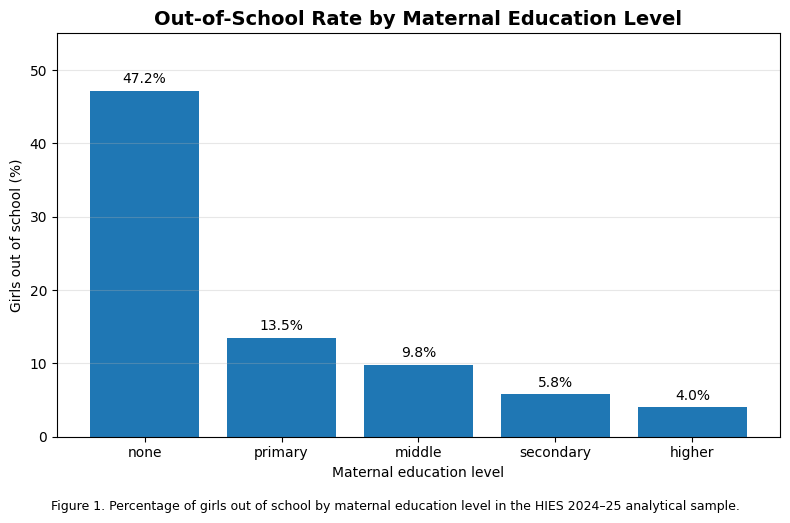

In [39]:
# 4. Publication-Quality Visualizations
# Maternal education vs out-of-school rate
plot_data = mom_edu_outcome.reset_index()

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    plot_data["mom_educ_level"],
    plot_data["Out of School (%)"]
)

ax.set_title(
    "Out-of-School Rate by Maternal Education Level",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Maternal education level")
ax.set_ylabel("Girls out of school (%)")

ax.set_ylim(0, 55)

# Add values above bars
for i, value in enumerate(plot_data["Out of School (%)"]):
    ax.text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )

ax.grid(axis="y", alpha=0.3)

fig.text(
    0.5,
    -0.03,
    "Figure 1. Percentage of girls out of school by maternal education level "
    "in the HIES 2024–25 analytical sample.",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()

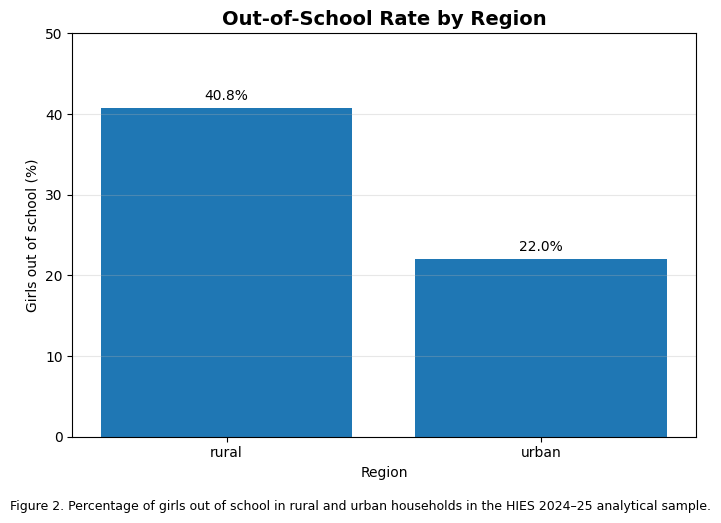

In [40]:
# region x out_of_school
plot_data = region_outcome.reset_index()

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    plot_data["region"],
    plot_data["Out of School (%)"]
)

ax.set_title(
    "Out-of-School Rate by Region",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Region")
ax.set_ylabel("Girls out of school (%)")

ax.set_ylim(0, 50)

for i, value in enumerate(plot_data["Out of School (%)"]):
    ax.text(
        i,
        value + 1,
        f"{value:.1f}%",
        ha="center"
    )

ax.grid(axis="y", alpha=0.3)

fig.text(
    0.5,
    -0.03,
    "Figure 2. Percentage of girls out of school in rural and urban households "
    "in the HIES 2024–25 analytical sample.",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()

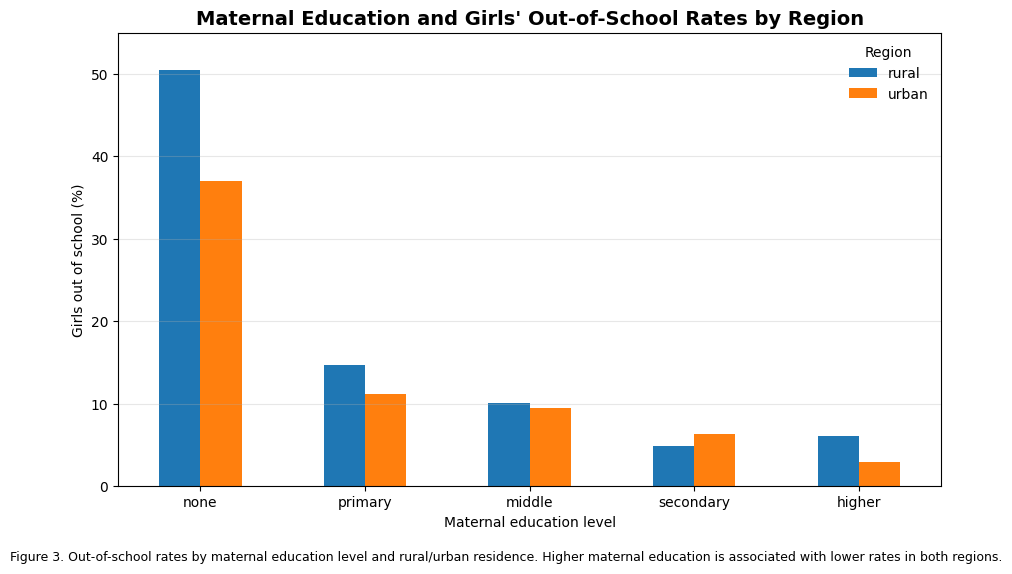

In [41]:
# Maternal education × region x out_of_school
edu_region_plot = edu_region.pivot(
    index="mom_educ_level",
    columns="region",
    values="Out of School (%)"
)

# Keep education categories in logical order
education_order = [
    "none",
    "primary",
    "middle",
    "secondary",
    "higher"
]

edu_region_plot = edu_region_plot.reindex(education_order)

fig, ax = plt.subplots(figsize=(9, 5.5))

edu_region_plot.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Maternal Education and Girls' Out-of-School Rates by Region",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Maternal education level")
ax.set_ylabel("Girls out of school (%)")

ax.set_ylim(0, 55)

ax.legend(
    title="Region",
    frameon=False
)

ax.tick_params(axis="x", rotation=0)

ax.grid(axis="y", alpha=0.3)

fig.text(
    0.5,
    -0.03,
    "Figure 3. Out-of-school rates by maternal education level and rural/urban "
    "residence. Higher maternal education is associated with lower rates in both regions.",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()

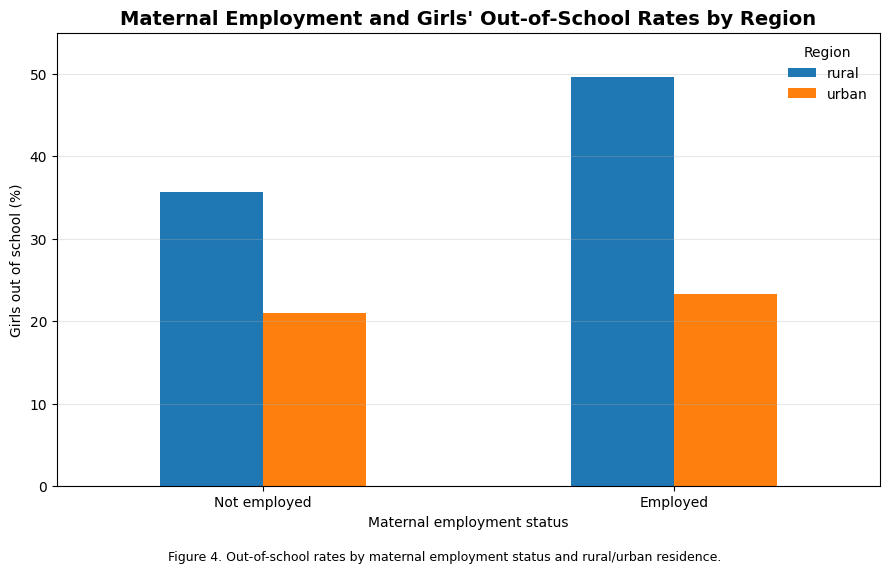

In [42]:
# Maternal employment × region × out_of_school

employment_region_plot = employment_region.pivot(
    index="mom_employed",
    columns="region",
    values="Out of School (%)"
)

# Keep employment categories in logical order
employment_order = [
    0,
    1
]

employment_region_plot = employment_region_plot.reindex(
    employment_order
)

# Rename row labels for readability
employment_region_plot.index = [
    "Not employed",
    "Employed"
]

fig, ax = plt.subplots(figsize=(9, 5.5))

employment_region_plot.plot(
    kind="bar",
    ax=ax
)

ax.set_title(
    "Maternal Employment and Girls' Out-of-School Rates by Region",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Maternal employment status")
ax.set_ylabel("Girls out of school (%)")

ax.set_ylim(0, 55)

ax.legend(
    title="Region",
    frameon=False
)

ax.tick_params(axis="x", rotation=0)

ax.grid(axis="y", alpha=0.3)

fig.text(
    0.5,
    -0.03,
    "Figure 4. Out-of-school rates by maternal employment status and rural/urban "
    "residence.",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()

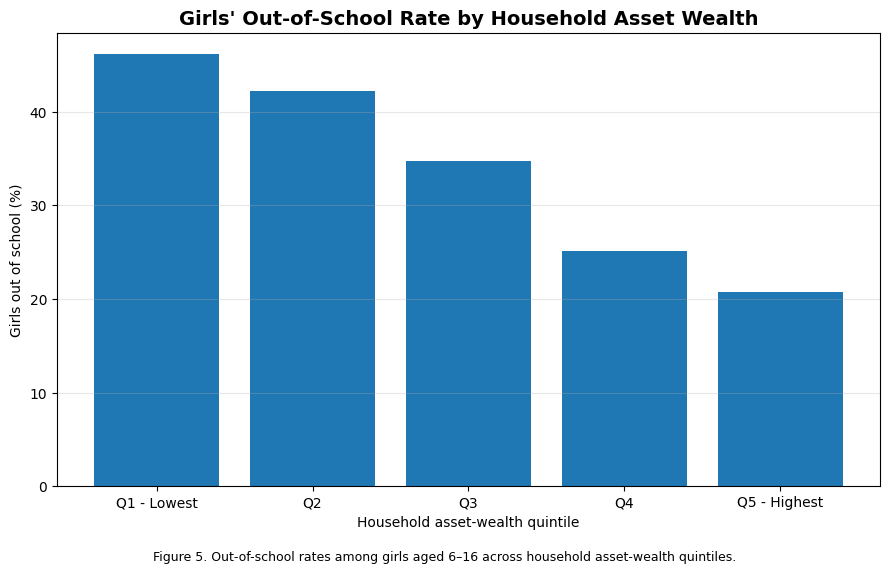

In [43]:
plot_data = wealth_outcome.reset_index()

fig, ax = plt.subplots(figsize=(9, 5.5))

ax.bar(
    plot_data["wealth_quintile"].astype(str),
    plot_data["Out of School (%)"]
)

ax.set_title(
    "Girls' Out-of-School Rate by Household Asset Wealth",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Household asset-wealth quintile")
ax.set_ylabel("Girls out of school (%)")

ax.grid(axis="y", alpha=0.3)

fig.text(
    0.5,
    -0.03,
    "Figure 5. Out-of-school rates among girls aged 6–16 across "
    "household asset-wealth quintiles.",
    ha="center",
    fontsize=9
)

plt.tight_layout()
plt.show()

**section 4**


**H1: maternal education impact**

Ho : Maternal education has no impact on girl child's likelihood of being out of school, holding all the other confounding variables constant. All the education coefficients (primary, middle, secondary, higher) equal zero.

Ha: Maternal education decreases the likelihood of a girl being out of school, holding all the other confounding variables constant (At least one education coefficient is not zero).


**H2: collective Maternal education and rural residence impact**

Ho : The impact of maternal education on a girl child being out of school is the same in rural and urban areas, holding all the other confounding variables constant.

Ha : The impact of maternal education on a girl child being out of school differs between rural and urban areas, holding all the other confounding variables constant.


**H3: Mother's employment impact**

Ho: The status of a mother being employed has no impact on a girl child's likelihood of being out of school, holding all the other confounding variables constant.

Ha: The status of a mother being employed decreases a girl child's likelihood of being out of school, holding all the other confounding variables constant.


**H4: collective mother's employment and rural residence impact**

Ho : The association between maternal employment and out-of-school status is the same in rural and urban areas, holding all the other confounding variables constant.

Ha : The association between maternal employment and out-of-school status differs in rural and urban areas, holding all the other confounding variables constant.

**H5: household wealth impact**

Ho: A girl child's chance of being out of school does not differ by her household's wealth level, holding all the other confounding variables constant.

Ha: A girl child's chance of being out of school differs by her household's wealth level, holding all the other confounding variables constant.


